# BioSleep-v5: Dependency-Aware Wake–Sleep–REM Structured Pruning
### with gate-Fisher saliency, FLOPs-targeted homeostatic budgets, dynamic regrowth and coverage replay

**Journal-track successor of BioSleep-v4.** This notebook is fully self-contained: it writes its
own Python package (`biosleep/`, 14 modules + a 22-test `pytest` suite) into the Colab VM, downloads a
**public, license-clean rice-leaf-disease dataset from the Hugging Face Hub (no Kaggle token)**, and
saves **every step of every run to Google Drive** so that a disconnected Colab session resumes exactly
where it stopped.

#### What changed from v4, and why

| v4 problem | Consequence | v5 fix |
|---|---|---|
| `import biosleep` — package not shipped | notebook could not run | package written by the notebook itself (§2), tested before use |
| BioSleep got 51 epochs, baselines 16 | accuracy gap confounded with compute | **identical optimiser-step budget, identical KD recipe, same dense start** for every method (verified in the earlier test suite) |
| Arms ended at different sparsities | accuracy comparison uninterpretable | every method must hit the **same FLOPs target** (50 % / 70 %), measured independently by Torch-Pruning |
| Baselines: L1-filter (2016), LTH & magnitude (unstructured) | not "current"; unstructured gives no speed-up | 8 **structured, group-level** baselines: DepGraph, Taylor, Hessian/OBD, Network Slimming, LAMP, FPGM, magnitude, random — **verified equal to Torch-Pruning's own implementations** |
| Residual-coupled channels never pruned | capped achievable FLOPs reduction on ResNet-50 | **DepGraph dependency groups**: every channel prunable, compaction verified exact |
| 80/20 train/test, no validation split | model selection on the test set | 70/15/15 split, selection on **val only**; exact + near-duplicate images grouped so they never straddle splits |
| t-test vs *unpruned*, n = 3 | wrong comparison, underpowered | paired tests **vs every baseline**, Holm-corrected, bootstrap CIs, power analysis |
| Otsu budget with no unimodality guard | could remove ~0 or ~all channels in a cycle | Otsu proposal clipped to [0.5, 1.5] × even share of the remaining FLOPs gap, falls back when η < 0.35 |
| Replay coverage on logits | weak geometry | teacher **penultimate embeddings**, class-balanced facility location |

#### Status
Pipeline correctness (exact compaction on ResNet-18/50, FLOPs-target accuracy, bit-exact resume after
simulated disconnects in every phase, leakage-safe splitting, baseline fidelity to Torch-Pruning) was
already established by the 22-test suite and the in-notebook checks in an earlier run. **This version
is set up to run the real protocol, full scale, on the original dataset** (`rice4_leafnet`, plus
`dhan_shomadhan` for the cross-dataset check): the synthetic-verifier fallback and the
demonstration/verification cells have been removed, `TIER` is fixed to `full` (5 seeds ×
{30, 50, 70} % FLOPs targets × 9 methods), and the notebook now requires a GPU runtime with internet
access — it raises immediately rather than silently falling back if either is missing.

## 0. How to run it in Colab
1. **Runtime → Change runtime type → GPU** (T4 works; A100/L4 is ~3× faster).
2. **Runtime → Run all.** Approve the Google Drive prompt.
3. If Colab disconnects: reconnect and **Run all** again. The dataset cache is re-used from Drive,
   finished runs are skipped instantly, and the interrupted run resumes at the step after its last
   checkpoint. (The unit-test suite in §2.16 is skipped by default — `RUN_TESTS = False` — since
   correctness was already verified; flip it to `True` if you change any `biosleep/*.py` cell.)
4. The compute tier in §5 (`TIER`) is fixed to `"full"` for this run (5 seeds, {30, 50, 70} % FLOPs
   targets, all 9 methods). The notebook prints a time estimate before starting.

Everything lives under `MyDrive/BioSleep_v5/`: `data/` (image cache + manifest), `runs/<run_id>/`
(checkpoints, results, final compacted models), `results/`, `figs/`, `code_snapshots/`.

## 1. Setup

In [ ]:
import sys, subprocess, importlib, os
def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

try:
    import torch_pruning as _tp
    assert _tp.__version__.startswith("1.6"), _tp.__version__
except Exception:
    _pip("torch-pruning==1.6.1")          # pinned: baseline fidelity is verified against this version
for mod, pkg in [("huggingface_hub", "huggingface_hub"), ("pyarrow", "pyarrow"), ("pytest", "pytest")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        _pip(pkg)
print("dependencies OK")

dependencies OK


In [ ]:
import json, time, shutil, warnings, hashlib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
import torch, torch_pruning as tp
warnings.filterwarnings("ignore", category=UserWarning)

print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | torch-pruning {tp.__version__}")
print("CUDA:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available (CPU only)")
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .3, "savefig.bbox": "tight"})
os.makedirs("biosleep_v5/biosleep", exist_ok=True); os.makedirs("biosleep_v5/tests", exist_ok=True)

Python 3.13.15 | PyTorch 2.11.0+cu130 | torch-pruning 1.6.0
CUDA: Tesla T4


## 2. The `biosleep` package (written by this notebook)
Each cell below writes one module. Read them top to bottom as the method's implementation; edit a
cell and re-run it (plus the import cell in §2.15) to change behaviour. Any edit that changes a
`Config` field changes every affected `run_id`, so stale checkpoints are never silently reused.

### 2.1 `config.py` — one dataclass describes a run

`run_id()` hashes every result-affecting field; `dense_id()` hashes only what the dense model depends on, so **every method at a given seed starts from the same dense checkpoint**.

In [ ]:
%%writefile biosleep_v5/biosleep/config.py
"""Experiment configuration.

Every run is fully described by one `Config`. `run_id()` hashes every field that
can change a result, so a checkpoint is never silently reused after a
hyper-parameter change. `dense_id()` hashes only the fields the shared dense
(unpruned) model depends on, so all pruning methods for a given seed start from
the *same* dense checkpoint -- a fairness requirement, not just a time saver.
"""
from __future__ import annotations

import dataclasses
import hashlib
import json
from dataclasses import dataclass, asdict, field

# methods that prune with a criterion-only, one-shot-per-cycle schedule (baselines)
BASELINES = ("depgraph", "magnitude", "taylor", "hessian", "slimming", "lamp", "fpgm", "random")
METHODS = ("dense", "ours") + BASELINES

# fields that never change a numeric result (labels, logging)
_COSMETIC = {"arm", "verbose"}

# fields the dense model depends on
_DENSE_FIELDS = (
    "dataset", "data_root", "split_seed", "cache_size", "backbone", "pretrained",
    "image_size", "batch_size", "num_workers", "dense_epochs", "lr_dense",
    "momentum", "weight_decay", "label_smoothing", "warmup_epochs", "seed",
    "device", "amp", "channels_last", "synth_n_per_class", "synth_size",
    "num_classes",
)


@dataclass
class Config:
    # ---------------- data ----------------
    dataset: str = "rice4_leafnet"          # synthetic | rice4_leafnet | dhan_shomadhan | imagefolder
    data_root: str | None = None        # only for dataset="imagefolder"
    num_classes: int = 0                # 0 = infer from the dataset manifest
    split_seed: int = 2026              # FIXED across seeds: every seed sees the same split
    cache_size: int = 256               # shorter side of the resized image cache
    image_size: int = 224
    batch_size: int = 64
    eval_batch_size: int = 128
    num_workers: int = 2
    synth_n_per_class: int = 60         # synthetic verifier only
    synth_size: int = 64

    # ---------------- model ----------------
    backbone: str = "resnet50"          # resnet50 | resnet18 | resnet_tiny
    pretrained: bool = True

    # ---------------- method ----------------
    method: str = "ours"                # see METHODS
    target_flops_reduction: float = 0.5 # fraction of dense FLOPs to remove
    max_group_prune_ratio: float = 0.9  # never remove more than this of any channel group

    # ---------------- schedule (identical budget for every method) ----------------
    dense_epochs: int = 30
    cycles: int = 5
    cycle_epochs: int = 4               # training epochs (or epoch-equivalents) per cycle
    finetune_epochs: int = 15

    # ---------------- optimisation ----------------
    lr_dense: float = 0.01
    lr_prune: float = 0.005
    lr_ft: float = 0.005
    momentum: float = 0.9
    weight_decay: float = 5e-5
    label_smoothing: float = 0.1
    warmup_epochs: int = 1
    kd_alpha: float = 0.5               # weight of distillation from the dense teacher
    kd_T: float = 4.0

    # ---------------- ours: BioSleep-v5 ----------------
    criterion: str = "fisher"           # fisher | activation | magnitude | random
    flops_aware: bool = True            # rank by importance per FLOP (knapsack rule)
    budget_mode: str = "homeostatic"    # homeostatic (Otsu, clipped) | cubic
    regrow: bool = True                 # revive pruned channels by gate-gradient (DST)
    regrow_frac: float = 0.2            # initial revive fraction (cosine-decayed to 0)
    rem_epochs: int = 1                 # of each cycle's cycle_epochs, how many are REM
    buffer_mode: str = "coverage"       # coverage | random | none
    buffer_size: int = 256
    ema_mode: str = "geometric"         # geometric (N1, derived rho) | fixed | none
    ema_rho_fixed: float = 0.999

    # ---------------- baselines ----------------
    calib_batches: int = 16             # gradient batches for taylor / hessian scores
    depgraph_reg: float = 5e-4          # group-L2 sparse learning (DepGraph)
    slimming_reg: float = 1e-4          # BN-L1 (Network Slimming)

    # ---------------- runtime ----------------
    seed: int = 0
    device: str = "cuda"
    amp: bool = True
    channels_last: bool = True
    arm: str = ""                       # free-text label (not hashed)
    verbose: bool = True

    # ------------------------------------------------------------------
    def __post_init__(self):
        assert self.method in METHODS, f"unknown method {self.method!r}; choose from {METHODS}"
        assert 0.0 < self.target_flops_reduction < 1.0 or self.method == "dense"
        assert 0 <= self.rem_epochs < self.cycle_epochs, "need at least one wake epoch per cycle"
        assert self.criterion in ("fisher", "activation", "magnitude", "random")
        assert self.budget_mode in ("homeostatic", "cubic")
        assert self.buffer_mode in ("coverage", "random", "none")
        assert self.ema_mode in ("geometric", "fixed", "none")

    def replace(self, **kw) -> "Config":
        return dataclasses.replace(self, **kw)

    def to_dict(self) -> dict:
        return asdict(self)

    def _hash(self, keys) -> str:
        d = {k: v for k, v in asdict(self).items() if k in keys}
        return hashlib.sha1(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:12]

    def run_id(self) -> str:
        keys = [k for k in asdict(self) if k not in _COSMETIC]
        tag = self.method if self.method == "dense" else f"{self.method}_f{int(round(100*self.target_flops_reduction))}"
        return f"{tag}_s{self.seed}_{self._hash(keys)}"

    def dense_id(self) -> str:
        return f"dense_s{self.seed}_{self._hash(_DENSE_FIELDS)}"

    def dense_config(self) -> "Config":
        return self.replace(method="dense", arm="dense")

Writing biosleep_v5/biosleep/config.py


### 2.2 `utils.py` — seeding, RNG capture, Drive

RNG state (Python, NumPy, torch, CUDA) is saved in every checkpoint.

In [ ]:
%%writefile biosleep_v5/biosleep/utils.py
"""Small runtime utilities: seeding, RNG capture/restore, Drive mounting, timing."""
from __future__ import annotations

import os
import random
import time
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import torch


def in_colab() -> bool:
    try:
        import google.colab  # noqa: F401
        return True
    except Exception:
        return False


def mount_drive(subdir: str = "BioSleep_v5", local_fallback: str = "./biosleep_v5_store") -> Path:
    """Mount Google Drive in Colab and return a persistent root folder.

    Outside Colab, returns a local folder instead (clearly announced) so the rest
    of the notebook runs unchanged -- only persistence across VMs differs.
    """
    if in_colab():
        from google.colab import drive
        if not os.path.isdir("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        root = Path("/content/drive/MyDrive") / subdir
    else:
        print(f"[biosleep] not in Colab -> using LOCAL store {Path(local_fallback).resolve()} "
              "(checkpoints will NOT survive a new VM)")
        root = Path(local_fallback)
    root.mkdir(parents=True, exist_ok=True)
    return root


def resolve_device(requested: str) -> torch.device:
    if requested.startswith("cuda") and not torch.cuda.is_available():
        return torch.device("cpu")
    return torch.device(requested)


def seed_everything(seed: int, deterministic: bool = False) -> None:
    random.seed(seed)
    np.random.seed(seed % (2**32))
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = not deterministic
    torch.backends.cudnn.deterministic = deterministic


def get_rng_state() -> dict:
    st = {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state()}
    if torch.cuda.is_available():
        st["cuda"] = torch.cuda.get_rng_state_all()
    return st


def set_rng_state(st: dict) -> None:
    random.setstate(st["python"])
    np.random.set_state(st["numpy"])
    torch.set_rng_state(st["torch"])
    if "cuda" in st and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(st["cuda"])


def stable_seed(*parts) -> int:
    """Deterministic 31-bit seed from arbitrary parts (independent of PYTHONHASHSEED)."""
    import hashlib
    h = hashlib.sha1("|".join(map(str, parts)).encode()).hexdigest()
    return int(h[:8], 16) & 0x7FFFFFFF


@contextmanager
def timer(label: str, verbose: bool = True):
    t0 = time.time()
    yield
    if verbose:
        print(f"  [{label}] {time.time() - t0:.1f}s")


def log(cfg_or_flag, *msg):
    verbose = cfg_or_flag if isinstance(cfg_or_flag, bool) else getattr(cfg_or_flag, "verbose", True)
    if verbose:
        print(*msg, flush=True)

Writing biosleep_v5/biosleep/utils.py


### 2.3 `data.py` — public datasets, leakage-safe splits, Drive cache

Download from the Hugging Face Hub → canonical labels → exact (MD5) and near-duplicate (64-bit aHash, Hamming ≤ 4) grouping → **group-aware** stratified 70/15/15 split with a fixed split seed → resized JPEG cache + `manifest.json` on Drive. Loaders are re-created per epoch with a generator seeded by the step identity, which is what makes resume exact.

In [ ]:
%%writefile biosleep_v5/biosleep/data.py
"""Dataset acquisition, leakage-safe splitting, caching and loaders.

Public, license-clean sources (no Kaggle token needed; downloaded from the
Hugging Face Hub with `huggingface_hub.snapshot_download`, no login required):

* ``rice4_leafnet``  -- LeafNet75/Rice-Disease-Classification-Dataset
  (Apache-2.0; ~4,078 field images; Brown Spot / Healthy / Leaf Blast / Neck Blast)
* ``dhan_shomadhan`` -- Project-AgML/Dhan-Shomadhan_rice_leaf_disease_classification
  (CC-BY-4.0; 1,106 images of Bangladeshi local rice; 5 diseases, field + white
  background; the raw labels contain spelling variants -- e.g. "Browon Spot",
  "Rice Turgro", "Shath Blight" -- which are merged into 5 canonical classes here)
* ``imagefolder``    -- any local folder-per-class dataset (e.g. the 6-class Kaggle
  set used by the conference paper, if you already have it)
* ``synthetic``      -- procedurally generated verifier, for pipeline checks only

Every source goes through the same pipeline:
  raw images -> canonical label -> exact-duplicate removal (MD5) ->
  near-duplicate grouping (64-bit average hash, Hamming <= 4) ->
  group-aware stratified 70/15/15 split with a FIXED split seed ->
  resized JPEG cache + manifest.json (both stored on Drive).

Near-duplicate grouping matters: public leaf-disease sets often contain the same
photo re-saved or lightly re-cropped. Randomly splitting such pairs across train
and test inflates accuracy and hides differences between pruning methods.
"""
from __future__ import annotations

import hashlib
import io
import json
import os
import re
import shutil
import tarfile
import zipfile
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T

from .utils import stable_seed

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}


def _norm(s: str) -> str:
    return re.sub(r"[^a-z]", "", str(s).lower())


@dataclass
class DatasetSpec:
    key: str
    hf_repo: str | None
    kind: str                     # folder | parquet | local | synthetic
    aliases: dict                 # normalised raw label -> canonical class
    license: str
    citation: str
    note: str = ""


DATASETS = {
    "rice4_leafnet": DatasetSpec(
        key="rice4_leafnet",
        hf_repo="LeafNet75/Rice-Disease-Classification-Dataset",
        kind="folder",
        aliases={"brownspot": "brown_spot", "healthy": "healthy",
                 "leafblast": "leaf_blast", "neckblast": "neck_blast"},
        license="Apache-2.0",
        citation="LeafNet75, Rice Disease Classification Dataset, Hugging Face Hub (formerly Subh775/...).",
        note="4 classes, ~4,078 field images."),
    "dhan_shomadhan": DatasetSpec(
        key="dhan_shomadhan",
        hf_repo="Project-AgML/Dhan-Shomadhan_rice_leaf_disease_classification",
        kind="parquet",
        aliases={"brownspot": "brown_spot", "browonspot": "brown_spot",
                 "leafscaled": "leaf_scald", "leafscald": "leaf_scald",
                 "riceblast": "rice_blast",
                 "ricetungro": "tungro", "riceturgro": "tungro",
                 "shathblight": "sheath_blight", "sheathblight": "sheath_blight"},
        license="CC-BY-4.0",
        citation="M. F. Hossain et al., Dhan-Shomadhan: A dataset of rice leaf disease classification "
                 "for Bangladeshi local rice, arXiv:2309.07515 (Mendeley Data doi:10.17632/znsxdctwtt.1).",
        note="5 canonical classes after merging label spelling variants; 1,106 images."),
    "imagefolder": DatasetSpec("imagefolder", None, "local", {}, "user-supplied", "user-supplied"),
    "synthetic": DatasetSpec("synthetic", None, "synthetic", {}, "n/a",
                             "procedural verifier (pipeline checks only)"),
}


# ----------------------------------------------------------------------------- raw iteration
def _extract_archives(root: Path) -> None:
    for p in list(root.rglob("*")):
        if p.suffix.lower() == ".zip":
            with zipfile.ZipFile(p) as z:
                z.extractall(p.parent / (p.stem + "_unzipped"))
        elif p.name.endswith((".tar", ".tar.gz", ".tgz")):
            with tarfile.open(p) as t:
                t.extractall(p.parent / (p.name.split(".")[0] + "_untarred"))


def _resolve_alias(name_norm: str, aliases: dict) -> str | None:
    """Map a normalised folder/label name to its canonical class.

    Tries an exact key match first, then falls back to substring containment so a folder
    name carrying extra tokens (e.g. a PlantVillage-style ``Rice___Brown_Spot``, which
    normalises to ``ricebrownspot``) still resolves against a plain ``brownspot`` alias key.
    Returns None -- and lets the caller report the raw name -- on no match or genuine
    ambiguity (more than one distinct canonical class would fit as a substring)."""
    if name_norm in aliases:
        return aliases[name_norm]
    hits = {v for k, v in aliases.items() if k and k in name_norm}
    return hits.pop() if len(hits) == 1 else None


def iter_folder(root: Path, aliases: dict | None):
    """Yield (bytes, raw_label). Label = nearest ancestor folder that resolves to a known
    class (see `_resolve_alias`). With aliases=None (imagefolder), the immediate parent
    folder is the label. If no ancestor resolves, the immediate parent's name is still
    yielded as the raw label: `prepare_dataset` makes the same resolution decision and
    counts/report unmatched names there, instead of them being silently dropped here."""
    for p in sorted(root.rglob("*")):
        if p.suffix.lower() not in IMG_EXT or not p.is_file():
            continue
        if aliases is None:
            label = p.parent.name
        else:
            label = None
            for anc in p.parents:
                if anc == root.parent:
                    break
                if _resolve_alias(_norm(anc.name), aliases) is not None:
                    label = anc.name
                    break
            if label is None:
                label = p.parent.name          # best-effort raw label, for diagnostics
        yield p.read_bytes(), label


def iter_parquet(root: Path):
    import pyarrow.parquet as pq
    files = sorted(root.rglob("*.parquet"))
    if not files:
        raise FileNotFoundError(f"no parquet files under {root}")
    for f in files:
        table = pq.read_table(f)
        names = None
        feats = table.schema.metadata or {}
        # recover ClassLabel names from HF metadata if the label column is an int
        if b"huggingface" in feats:
            try:
                meta = json.loads(feats[b"huggingface"])
                names = meta["info"]["features"]["label"]["names"]
            except Exception:
                names = None
        cols = table.to_pydict()
        for img, lab in zip(cols["image"], cols["label"]):
            data = img["bytes"] if isinstance(img, dict) else img
            if data is None and isinstance(img, dict) and img.get("path"):
                data = Path(img["path"]).read_bytes()
            raw = names[lab] if (names is not None and isinstance(lab, int)) else lab
            yield data, str(raw)


def _ahash(img: Image.Image) -> int:
    g = np.asarray(img.convert("L").resize((8, 8), Image.BILINEAR), dtype=np.float32)
    bits = (g > g.mean()).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)


def _near_dup_groups(hashes: list[int], max_hamming: int = 4) -> list[int]:
    """Union-find over pairs with Hamming distance <= max_hamming (vectorised)."""
    n = len(hashes)
    parent = list(range(n))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    h = np.array(hashes, dtype=np.uint64)
    for i in range(n):
        x = np.bitwise_xor(h[i + 1:], h[i])
        # popcount on uint64
        cnt = np.zeros(len(x), dtype=np.int64)
        for s in range(0, 64, 8):
            cnt += _POP8[((x >> np.uint64(s)) & np.uint64(255)).astype(np.int64)]
        for j in np.nonzero(cnt <= max_hamming)[0]:
            a, b = find(i), find(i + 1 + int(j))
            if a != b:
                parent[b] = a
    return [find(i) for i in range(n)]


_POP8 = np.array([bin(i).count("1") for i in range(256)], dtype=np.int64)


def _group_stratified_split(labels, groups, fracs=(0.70, 0.15, 0.15), seed=2026):
    """Assign WHOLE near-duplicate groups to splits (no group ever straddles two splits),
    stratified by each group's majority class."""
    rng = np.random.RandomState(seed)
    labels, groups = np.asarray(labels), np.asarray(groups)
    gids = np.unique(groups)
    major = {g: np.bincount(labels[groups == g]).argmax() for g in gids}
    sizes = {g: int((groups == g).sum()) for g in gids}
    split_of = {}
    for c in sorted(set(major.values())):
        gs = np.array([g for g in gids if major[g] == c])
        rng.shuffle(gs)
        total = sum(sizes[g] for g in gs)
        acc, cut1, cut2 = 0, fracs[0] * total, (fracs[0] + fracs[1]) * total
        for g in gs:
            split_of[g] = "train" if acc < cut1 else ("val" if acc < cut2 else "test")
            acc += sizes[g]
    return [split_of[g] for g in groups]


# ----------------------------------------------------------------------------- synthetic verifier
def _synthetic_items(n_per_class: int, size: int, num_classes: int = 4, seed: int = 0):
    """Class = texture orientation/frequency + lesion colour; heavy noise. Pipeline checks only."""
    rng = np.random.RandomState(seed)
    yy, xx = np.mgrid[0:size, 0:size] / size
    for c in range(num_classes):
        for i in range(n_per_class):
            ang = np.pi * c / num_classes + rng.normal(0, 0.3)
            freq = 3 + 1.3 * c + rng.normal(0, 0.6)
            base = 0.5 + 0.25 * np.sin(2 * np.pi * freq * (xx * np.cos(ang) + yy * np.sin(ang)))
            img = np.stack([base * 0.4, base * 0.8, base * 0.3], -1)
            for _ in range(rng.randint(2, 5)):  # lesions
                cx, cy, r = rng.rand(), rng.rand(), 0.05 + 0.08 * rng.rand()
                m = ((xx - cx) ** 2 + (yy - cy) ** 2) < r ** 2
                col = np.array([0.6 + 0.04 * c, 0.4 - 0.03 * c, 0.1 + 0.04 * (c % 2)]) + rng.normal(0, 0.08, 3)
                img[m] = 0.5 * img[m] + 0.5 * col
            img = np.clip(img + rng.normal(0, 0.27, img.shape), 0, 1)
            buf = io.BytesIO()
            Image.fromarray((img * 255).astype(np.uint8)).save(buf, format="PNG")
            yield buf.getvalue(), f"class_{c}"


# ----------------------------------------------------------------------------- build / load manifest
def prepare_dataset(cfg, store_root: str | Path, raw_dir: str | Path | None = None,
                    force: bool = False, verbose: bool = True) -> Path:
    """Acquire -> clean -> split -> cache. Idempotent: returns the manifest if already built.

    The cache lives under ``store_root/data/<dataset>_<cache_size>`` (Drive in Colab),
    so the download and preprocessing happen once per dataset, not once per session.
    """
    spec = DATASETS[cfg.dataset]
    tag = cfg.dataset if cfg.dataset != "synthetic" else f"synthetic_n{cfg.synth_n_per_class}_s{cfg.synth_size}"
    cache = Path(store_root) / "data" / f"{tag}_{cfg.cache_size}_split{cfg.split_seed}"
    manifest = cache / "manifest.json"
    if manifest.exists() and not force:
        return manifest
    if cache.exists():
        shutil.rmtree(cache)
    (cache / "images").mkdir(parents=True)

    # 1. acquire raw iterator
    if spec.kind == "synthetic":
        items = _synthetic_items(cfg.synth_n_per_class, cfg.synth_size, max(cfg.num_classes, 4) if cfg.num_classes else 4)
        aliases = None
    elif spec.kind == "local":
        assert cfg.data_root and os.path.isdir(cfg.data_root), "set cfg.data_root to a folder-per-class directory"
        items, aliases = iter_folder(Path(cfg.data_root), None), None
    else:
        raw_dir = Path(raw_dir or "/tmp/biosleep_raw") / cfg.dataset
        done_flag = raw_dir / ".download_complete"
        if not done_flag.exists():               # absent flag = never downloaded or interrupted -> (re)sync
            from huggingface_hub import snapshot_download
            if verbose:
                print(f"[data] downloading {spec.hf_repo} from the Hugging Face Hub (resumable) ...")
            raw_dir.mkdir(parents=True, exist_ok=True)
            snapshot_download(repo_id=spec.hf_repo, repo_type="dataset", local_dir=str(raw_dir))
            _extract_archives(raw_dir)
            done_flag.write_text("ok")
        aliases = spec.aliases
        has_parquet = any(raw_dir.rglob("*.parquet"))
        has_images = any(p.suffix.lower() in IMG_EXT for p in raw_dir.rglob("*"))
        use_parquet = (spec.kind == "parquet" and has_parquet) or (not has_images and has_parquet)
        if verbose:
            print(f"[data] reading {'parquet shards' if use_parquet else 'image folders'} under {raw_dir}")
        items = iter_parquet(raw_dir) if use_parquet else iter_folder(raw_dir, aliases)

    # 2. canonicalise, dedup, resize, write cache
    records, seen_md5, n_exact_dup, unknown = [], set(), 0, {}
    for data, raw_label in items:
        if aliases is None:
            label = raw_label
        else:
            label = _resolve_alias(_norm(raw_label), aliases)
            if label is None:
                unknown[raw_label] = unknown.get(raw_label, 0) + 1
                continue
        md5 = hashlib.md5(data).hexdigest()
        if md5 in seen_md5:
            n_exact_dup += 1
            continue
        seen_md5.add(md5)
        try:
            img = Image.open(io.BytesIO(data)).convert("RGB")
        except Exception:
            continue
        w, h = img.size
        s = cfg.cache_size / min(w, h)
        if s < 1:
            img = img.resize((max(1, round(w * s)), max(1, round(h * s))), Image.BICUBIC)
        rel = f"images/{label}/{md5[:16]}.jpg"
        (cache / "images" / label).mkdir(exist_ok=True)
        img.save(cache / rel, format="JPEG", quality=95)
        records.append({"path": rel, "label_name": label, "ahash": _ahash(img)})
    if unknown and verbose:
        print(f"[data] skipped images with unrecognised labels: {unknown}")
    if not records:
        raise RuntimeError(
            f"no images found for dataset {cfg.dataset!r} at {raw_dir}. "
            f"{'Unrecognised folder/label names: ' + str(unknown) if unknown else 'No image files were found under that path at all -- check the download.'}"
        )

    classes = sorted({r["label_name"] for r in records})
    groups = _near_dup_groups([r["ahash"] for r in records])
    labels = [classes.index(r["label_name"]) for r in records]
    splits = _group_stratified_split(labels, groups, seed=cfg.split_seed)
    for r, y, g, sp in zip(records, labels, groups, splits):
        r.update(label=y, group=int(g), split=sp)
        r.pop("ahash")
    n_groups_multi = sum(1 for g in set(groups) if groups.count(g) > 1)
    meta = {
        "dataset": cfg.dataset, "source": spec.hf_repo, "license": spec.license, "citation": spec.citation,
        "classes": classes, "n_images": len(records), "exact_duplicates_removed": n_exact_dup,
        "near_duplicate_groups": n_groups_multi, "split_seed": cfg.split_seed,
        "counts": {sp: {c: sum(1 for r in records if r["split"] == sp and r["label_name"] == c) for c in classes}
                   for sp in ("train", "val", "test")},
        "items": records,
    }
    tmp = manifest.with_suffix(".tmp")
    tmp.write_text(json.dumps(meta))
    os.replace(tmp, manifest)
    return manifest


def load_manifest(path: str | Path) -> dict:
    return json.loads(Path(path).read_text())


def describe_manifest(m: dict) -> str:
    lines = [f"dataset={m['dataset']}  images={m['n_images']}  classes={len(m['classes'])}  "
             f"exact-dups removed={m['exact_duplicates_removed']}  near-dup groups={m['near_duplicate_groups']}",
             f"source={m['source']}  license={m['license']}"]
    for sp, cnt in m["counts"].items():
        lines.append(f"  {sp:5s} " + "  ".join(f"{k}={v}" for k, v in cnt.items()) + f"   (total {sum(cnt.values())})")
    return "\n".join(lines)


# ----------------------------------------------------------------------------- torch datasets
class ManifestDataset(Dataset):
    def __init__(self, root: Path, items: list, transform):
        self.root, self.items, self.transform = Path(root), items, transform
        self.targets = [it["label"] for it in items]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        it = self.items[i]
        img = Image.open(self.root / it["path"]).convert("RGB")
        return self.transform(img), it["label"]


def build_transforms(image_size: int):
    train = T.Compose([
        T.RandomResizedCrop(image_size, scale=(0.35, 1.0)),
        T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
        T.ColorJitter(0.2, 0.2, 0.2, 0.02),
        T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
    evalt = T.Compose([
        T.Resize(int(round(image_size * 1.143))), T.CenterCrop(image_size),
        T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
    return train, evalt


class DataBundle:
    """Holds the three splits and builds per-epoch *seeded* loaders (resume-exact)."""

    def __init__(self, cfg, manifest_path: str | Path):
        self.cfg = cfg
        self.manifest_path = Path(manifest_path)
        m = load_manifest(manifest_path)
        self.meta = {k: v for k, v in m.items() if k != "items"}
        self.classes = m["classes"]
        root = self.manifest_path.parent
        ttr, tev = build_transforms(cfg.image_size)
        by = {sp: [it for it in m["items"] if it["split"] == sp] for sp in ("train", "val", "test")}
        self.train = ManifestDataset(root, by["train"], ttr)
        self.train_eval = ManifestDataset(root, by["train"], tev)   # for features / buffer selection
        self.val = ManifestDataset(root, by["val"], tev)
        self.test = ManifestDataset(root, by["test"], tev)

    @property
    def num_classes(self):
        return len(self.classes)

    def steps_per_epoch(self) -> int:
        return max(1, len(self.train) // self.cfg.batch_size)

    def _loader(self, ds, shuffle, seed, batch_size, drop_last):
        g = torch.Generator()
        g.manual_seed(seed)
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last,
                          num_workers=self.cfg.num_workers, generator=g,
                          pin_memory=torch.cuda.is_available(),
                          persistent_workers=False)

    def train_loader(self, *seed_parts):
        """A fresh loader whose shuffle *and* worker-augmentation RNG depend only on seed_parts."""
        return self._loader(self.train, True, stable_seed(self.cfg.seed, *seed_parts),
                            self.cfg.batch_size, drop_last=True)

    def subset_loader(self, indices, *seed_parts, shuffle=True):
        sub = torch.utils.data.Subset(self.train, list(indices))
        return self._loader(sub, shuffle, stable_seed(self.cfg.seed, *seed_parts),
                            min(self.cfg.batch_size, len(sub)), drop_last=False)

    def eval_loader(self, split: str):
        ds = {"val": self.val, "test": self.test, "train_eval": self.train_eval}[split]
        return self._loader(ds, False, 0, self.cfg.eval_batch_size, drop_last=False)

Writing biosleep_v5/biosleep/data.py


### 2.4 `models.py` — backbones

ResNet family (the dependency machinery is verified on these).

In [ ]:
%%writefile biosleep_v5/biosleep/models.py
"""Backbones. ResNet-family only: the dependency-group machinery is verified on these."""
from __future__ import annotations

import torch
import torch.nn as nn
import torchvision
from torchvision.models.resnet import BasicBlock, ResNet


def build_model(cfg, num_classes: int) -> nn.Module:
    if cfg.backbone == "resnet50":
        w = torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if cfg.pretrained else None
        m = torchvision.models.resnet50(weights=w)
    elif cfg.backbone == "resnet18":
        w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if cfg.pretrained else None
        m = torchvision.models.resnet18(weights=w)
    elif cfg.backbone == "resnet_tiny":        # verifier: same topology class, CPU-friendly
        m = ResNet(BasicBlock, [1, 1, 1, 1])
    else:
        raise ValueError(cfg.backbone)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m


def classifier(model: nn.Module) -> nn.Module:
    return model.fc


def forward_features(model: nn.Module, x: torch.Tensor) -> torch.Tensor:
    """Penultimate (post-avgpool) embedding of a torchvision ResNet -- works on compacted models too."""
    x = model.maxpool(model.relu(model.bn1(model.conv1(x))))
    x = model.layer4(model.layer3(model.layer2(model.layer1(x))))
    return torch.flatten(model.avgpool(x), 1)

Writing biosleep_v5/biosleep/models.py


### 2.5 `groups.py` — dependency groups, gates, FLOPs model, compaction

The core of C1 (§6). One gate per coupled channel group; training a gated network is identical to training the smaller network, but gates can be re-opened and give ∂L/∂g for free.

In [ ]:
%%writefile biosleep_v5/biosleep/groups.py
"""Dependency-aware channel groups, differentiable gates, an exact FLOPs model, and compaction.

Why this module exists (the v4 limitation it removes): v4 could only prune convolutions
whose output did not feed a residual sum. Here, Torch-Pruning's DependencyGraph (DepGraph,
Fang et al., CVPR 2023) partitions *every* prunable channel of the network into coupled
groups -- e.g. all the BN outputs, residual adds and downstream input slices that must be
removed together. Each group channel gets one gate g in {0,1}:

    out_bn[:, c] <- out_bn[:, c] * g[c]           (applied at every BN of the group)

Training a gated network is mathematically identical to training the physically smaller
network (a gated channel contributes exactly zero downstream, and receives zero gradient),
but it (a) lets pruned channels be *revived* (dynamic sparse training) and (b) gives
dL/dg for free after each backward pass -- the first-order Taylor / Fisher signal both for
removing active channels and for reviving inactive ones.

At the end, `compact()` physically removes gated channels with DepGraph's own pruning
functions; `tests/` verify logits match the gated model to float tolerance.
"""
from __future__ import annotations

import copy
from dataclasses import dataclass, field

import torch
import torch.nn as nn
import torch_pruning as tp

from .models import classifier


@dataclass
class Member:
    name: str
    kind: str            # conv_out | conv_in | bn | linear_in | linear_out
    idx: torch.Tensor    # member index for each root channel of the group


@dataclass
class Group:
    gid: int
    root_name: str
    root_kind: str       # conv | linear
    size: int
    offset: int
    members: list = field(default_factory=list)


def _kind_of(module, handler_name: str):
    if isinstance(module, nn.Conv2d):
        return "conv_out" if "out" in handler_name else "conv_in"
    if isinstance(module, nn.Linear):
        return "linear_out" if "out" in handler_name else "linear_in"
    if isinstance(module, nn.modules.batchnorm._BatchNorm):
        return "bn"
    return None


class GroupSpec:
    """Static description of all prunable channel groups of an (unpruned) model."""

    def __init__(self, model: nn.Module, image_size: int, device="cpu"):
        model = model.eval()
        ex = torch.randn(1, 3, image_size, image_size, device=device)
        name_of = {id(m): n for n, m in model.named_modules()}
        self.modules = dict(model.named_modules())
        DG = tp.DependencyGraph().build_dependency(model, example_inputs=ex)
        fc = classifier(model)
        raw_groups = DG.get_all_groups(ignored_layers=[fc], root_module_types=(nn.Conv2d, nn.Linear))

        self.groups: list[Group] = []
        offset = 0
        for g in raw_groups:
            root_dep, root_idxs = g[0].dep, g[0].idxs
            root_mod = root_dep.target.module
            size = len(root_idxs)
            grp = Group(gid=len(self.groups), root_name=name_of[id(root_mod)],
                        root_kind="conv" if isinstance(root_mod, nn.Conv2d) else "linear",
                        size=size, offset=offset)
            seen = set()
            for item in g:
                dep, idxs = item.dep, item.idxs
                mod = dep.target.module
                kind = _kind_of(mod, getattr(dep.handler, "__name__", str(dep.handler)))
                if kind is None or id(mod) not in name_of:
                    continue
                key = (name_of[id(mod)], kind)
                if key in seen:
                    continue
                seen.add(key)
                assert len(idxs) == size, "index mapping is not 1:1 with the root (unsupported topology)"
                idx = [int(getattr(i, "idx", i)) for i in idxs]
                grp.members.append(Member(key[0], kind, torch.tensor(idx, dtype=torch.long)))
            self.groups.append(grp)
            offset += size
        self.N = offset
        self.group_of = torch.cat([torch.full((g.size,), g.gid, dtype=torch.long) for g in self.groups])
        self.group_sizes = torch.tensor([g.size for g in self.groups])

        # --- gate placement: every BN member; groups without BN gate their conv/linear outputs
        self.gate_maps: dict[str, torch.Tensor] = {}
        for g in self.groups:
            bns = [mb for mb in g.members if mb.kind == "bn"]
            targets = bns if bns else [mb for mb in g.members if mb.kind in ("conv_out", "linear_out")]
            for mb in targets:
                gmap = self.gate_maps.setdefault(mb.name, torch.full(
                    (self._out_channels(self.modules[mb.name]),), -1, dtype=torch.long))
                gmap[mb.idx] = g.offset + torch.arange(g.size)
        for n, gm in self.gate_maps.items():
            assert (gm >= 0).all(), f"{n}: partially gated module (unsupported topology)"

        # --- FLOPs / params model: for every conv/linear, which global channel owns each in/out slice
        self.layers: dict[str, dict] = {}
        hw = {}
        hooks = [m.register_forward_hook(lambda mod, i, o, n=n: hw.__setitem__(n, o.shape[2:].numel()
                 if o.dim() == 4 else 1))
                 for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
        with torch.no_grad():
            model(ex)
        for h in hooks:
            h.remove()
        for n, m in model.named_modules():
            if isinstance(m, nn.Conv2d):
                k = m.kernel_size[0] * m.kernel_size[1]
                cin, cout, grp_ = m.in_channels, m.out_channels, m.groups
            elif isinstance(m, nn.Linear):
                k, cin, cout, grp_ = 1, m.in_features, m.out_features, 1
            else:
                continue
            assert grp_ == 1 or grp_ == cin == cout, f"{n}: grouped conv (non-depthwise) not supported"
            self.layers[n] = dict(k=k, hw=hw.get(n, 1), depthwise=(grp_ > 1),
                                  in_map=torch.full((cin,), -1, dtype=torch.long),
                                  out_map=torch.full((cout,), -1, dtype=torch.long),
                                  bias=getattr(m, "bias", None) is not None)
        for g in self.groups:
            gl = g.offset + torch.arange(g.size)
            for mb in g.members:
                if mb.name not in self.layers:
                    continue
                if mb.kind in ("conv_out", "linear_out"):
                    self.layers[mb.name]["out_map"][mb.idx] = gl
                elif mb.kind in ("conv_in", "linear_in"):
                    self.layers[mb.name]["in_map"][mb.idx] = gl
        self.dense_flops = self.flops(torch.ones(self.N))

    @staticmethod
    def _out_channels(m):
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            return m.num_features
        if isinstance(m, nn.Conv2d):
            return m.out_channels
        return m.out_features

    # ------------------------------------------------------------------ FLOPs model
    def _active(self, gates, mp):
        a = torch.ones(len(mp), dtype=gates.dtype, device=gates.device)
        own = mp >= 0
        a[own] = gates[mp[own].to(gates.device)]
        return a

    @torch.no_grad()
    def flops(self, gates: torch.Tensor) -> float:
        """Multiply-accumulates of conv + linear layers for a given binary gate vector."""
        gates = (gates > 0.5).float().cpu()
        tot = 0.0
        for L in self.layers.values():
            ai, ao = self._active(gates, L["in_map"]).sum(), self._active(gates, L["out_map"]).sum()
            tot += float(L["k"] * L["hw"] * (ao if L["depthwise"] else ai * ao))
        return tot

    @torch.no_grad()
    def marginal_cost(self, gates: torch.Tensor) -> torch.Tensor:
        """FLOPs removed by switching off each channel alone (given the current gates)."""
        gates = (gates > 0.5).float().cpu()
        cost = torch.zeros(self.N)
        for L in self.layers.values():
            ai, ao = self._active(gates, L["in_map"]).sum(), self._active(gates, L["out_map"]).sum()
            w = L["k"] * L["hw"]
            om, im = L["out_map"], L["in_map"]
            if L["depthwise"]:
                cost.index_add_(0, om[om >= 0], torch.full((int((om >= 0).sum()),), float(w)))
                continue
            cost.index_add_(0, om[om >= 0], torch.full((int((om >= 0).sum()),), float(w * ai)))
            cost.index_add_(0, im[im >= 0], torch.full((int((im >= 0).sum()),), float(w * ao)))
        return cost.clamp_min(1.0)

    def group_min_keep(self, max_ratio: float) -> torch.Tensor:
        return torch.clamp(torch.ceil(self.group_sizes.float() * (1 - max_ratio)), min=1).long()


class Gates:
    """Global binary gate vector + forward hooks. The same Gates can drive several model copies
    (student, EMA) as long as their module names match."""

    def __init__(self, spec: GroupSpec, device):
        self.spec = spec
        self.device = device
        self.g = torch.ones(spec.N, device=device)
        self._maps = {n: m.to(device) for n, m in spec.gate_maps.items()}
        self.act_sink = None          # optional callable(global_idx, per-channel mean |act|)

    def attach(self, model: nn.Module):
        mods = dict(model.named_modules())
        handles = []
        for n, gmap in self._maps.items():
            handles.append(mods[n].register_forward_hook(self._make_hook(gmap)))
        return handles

    def _make_hook(self, gmap):
        def hook(mod, inp, out):
            if self.act_sink is not None:
                with torch.no_grad():
                    red = (0, 2, 3) if out.dim() == 4 else (0,)
                    self.act_sink(gmap, out.detach().abs().float().mean(red))
            gv = self.g[gmap].to(out.dtype)
            return out * (gv.view(1, -1, 1, 1) if out.dim() == 4 else gv.view(1, -1))
        return hook

    @staticmethod
    def detach_hooks(handles):
        for h in handles:
            h.remove()

    def active_mask(self) -> torch.Tensor:
        return self.g.detach() > 0.5

    def sparsity(self) -> float:
        return 1.0 - float(self.active_mask().float().mean())


def compact(model: nn.Module, spec: GroupSpec, gates: torch.Tensor, image_size: int) -> nn.Module:
    """Return a physically smaller copy of `model` with every gated-off channel removed."""
    m = copy.deepcopy(model).cpu().eval()
    for mod in m.modules():          # drop any gate hooks carried over by deepcopy
        mod._forward_hooks.clear()
    mods = dict(m.named_modules())
    DG = tp.DependencyGraph().build_dependency(m, example_inputs=torch.randn(1, 3, image_size, image_size))
    gates = (gates.detach().cpu() > 0.5)
    for g in spec.groups:
        off = ~gates[g.offset:g.offset + g.size]
        idxs = torch.nonzero(off).flatten().tolist()
        if not idxs:
            continue
        root = mods[g.root_name]
        fn = tp.prune_conv_out_channels if g.root_kind == "conv" else tp.prune_linear_out_channels
        grp = DG.get_pruning_group(root, fn, idxs=idxs)
        grp.prune()
    for p_ in m.parameters():
        p_.grad = None
    return m

Writing biosleep_v5/biosleep/groups.py


### 2.6 `importance.py` — our gate-Fisher and 8 baseline criteria

Baselines follow Torch-Pruning's group-level definitions; fidelity is a unit test.

In [ ]:
%%writefile biosleep_v5/biosleep/importance.py
"""Channel-importance criteria, all expressed over the same global channel index space.

Ours ("fisher"): the empirical Fisher of the channel gate, E[(dL/dg)^2], averaged over the
*whole wake phase* (every training step, no extra passes). For a gate at 1 it is the
second-order estimate of the loss increase from removing the channel (Molchanov et al.
CVPR'19 derive the same quantity); for a gate at 0 it is the estimate of the loss decrease
from reviving it -- the signal used for regrowth. It is a loss-sensitivity, so it is
comparable across layers without per-layer normalisation.

Baselines (re-implemented on the same groups, following Torch-Pruning's group-level
definitions: per-member local score, mean over group members, then divided by the group
mean -- tp's default `group_reduction="mean", normalizer="mean"`):

  magnitude / depgraph  group L2 norm of all coupled weights (DepGraph, CVPR'23);
                        depgraph additionally trains with group-L2 sparse regularisation
  taylor                |w * dL/dw| summed over the coupled slice (Molchanov et al. '19)
  hessian               0.5 * w^2 * diag-Fisher(w) (OBD-style; tp GroupHessianImportance,
                        mini-batch granularity)
  slimming              |gamma| of the coupled BatchNorms, trained with BN-L1 (Liu et al. '17)
  lamp                  layer-adaptive magnitude score (Lee et al. ICLR'21), within group
  fpgm                  distance to the filters' geometric median (He et al. CVPR'19)

Fidelity (tests/test_biosleep.py::test_baselines_match_torch_pruning): magnitude, BN-scale,
FPGM, LAMP and Taylor scores equal Torch-Pruning 1.6.1's own classes to float precision.
Hessian equals tp's GroupHessianImportance on a single sample; for several samples we average
the squared gradients as OBD intends -- tp 1.6.1's `accumulate_grad` keys its dict by parameter
but tests membership by name, so it silently keeps only the LAST sample's gradient. Using the
intended estimator makes this baseline stronger, not weaker.
  random                uniform
"""
from __future__ import annotations

import torch
import torch.nn as nn

from .groups import GroupSpec


def _slices(mod: nn.Module, kind: str, idx: torch.Tensor, attr: str = "weight"):
    """Per-root-channel flattened parameter slice, shape (group_size, -1)."""
    t = getattr(mod, attr, None)
    if t is None:
        return None
    t = t if isinstance(t, torch.Tensor) else None
    idx = idx.to(t.device)
    if kind in ("conv_out", "linear_out", "bn"):
        return t.index_select(0, idx).reshape(len(idx), -1)
    if kind in ("conv_in", "linear_in"):
        if t.dim() < 2:
            return None
        return t.index_select(1, idx).transpose(0, 1).reshape(len(idx), -1)
    return None


def _member_tensors(model, spec: GroupSpec, g, want_grad=False):
    mods = dict(model.named_modules())
    out = []
    for mb in g.members:
        mod = mods[mb.name]
        for attr in ("weight", "bias"):
            if attr == "bias" and mb.kind in ("conv_in", "linear_in"):
                continue
            w = _slices(mod, mb.kind, mb.idx, attr)
            if w is None:
                continue
            gr = None
            if want_grad:
                p = getattr(mod, attr)
                if p.grad is None:
                    continue
                gr = _slices(_GradView(p.grad), mb.kind, mb.idx, "weight")
            out.append((mb, attr, w, gr))
    return out


class _GradView:
    def __init__(self, t):
        self.weight = t


def _group_normalise(score: torch.Tensor, spec: GroupSpec) -> torch.Tensor:
    out = score.clone()
    for g in spec.groups:
        s = out[g.offset:g.offset + g.size]
        out[g.offset:g.offset + g.size] = s / (s.mean() + 1e-12)
    return out


@torch.no_grad()
def magnitude_scores(model, spec, p=2):
    score = torch.zeros(spec.N)
    for g in spec.groups:
        vals = [w.detach().abs().pow(p).sum(1).float().cpu()
                for mb, attr, w, _ in _member_tensors(model, spec, g) if attr == "weight"]
        score[g.offset:g.offset + g.size] = torch.stack(vals).mean(0)
    return score


@torch.no_grad()
def lamp_scores(model, spec):
    base = magnitude_scores(model, spec)
    out = torch.zeros_like(base)
    for g in spec.groups:
        s = base[g.offset:g.offset + g.size]
        order = torch.argsort(s)
        sorted_s = s[order]
        tail = torch.flip(torch.cumsum(torch.flip(sorted_s, [0]), 0), [0])
        lamp = torch.empty_like(s)
        lamp[order] = sorted_s / (tail + 1e-12)
        out[g.offset:g.offset + g.size] = lamp
    return out


@torch.no_grad()
def bn_scale_scores(model, spec):
    mods = dict(model.named_modules())
    score = torch.zeros(spec.N)
    for g in spec.groups:
        vals = [mods[mb.name].weight.detach().abs().index_select(0, mb.idx.to(mods[mb.name].weight.device)).float().cpu()
                for mb in g.members if mb.kind == "bn"]
        if vals:
            score[g.offset:g.offset + g.size] = torch.stack(vals).mean(0)
        else:
            score[g.offset:g.offset + g.size] = magnitude_scores(model, spec)[g.offset:g.offset + g.size]
    return score


@torch.no_grad()
def fpgm_scores(model, spec, p=2):
    """Matches torch_pruning.importance.FPGMImportance: pairwise distances between |w|^p filter
    vectors, over both output and input slices of the group (BN excluded)."""
    mods = dict(model.named_modules())
    score = torch.zeros(spec.N)
    for g in spec.groups:
        vals = []
        for mb in g.members:
            if mb.kind == "bn":
                continue
            W = _slices(mods[mb.name], mb.kind, mb.idx, "weight").detach().float().abs().pow(p)
            vals.append(torch.cdist(W[None], W[None])[0].abs().sum(0).cpu())
        score[g.offset:g.offset + g.size] = torch.stack(vals).mean(0) if vals else 1.0
    return score


def gradient_scores(model, spec, batches, loss_fn, kind: str, device, amp_ctx):
    """Taylor (|w*g|) or OBD-Hessian (0.5*w^2*sum g^2) accumulated over calibration batches.
    Does not change weights, BN statistics (eval-mode BN) or optimiser state."""
    was_training = model.training
    model.eval()
    params = [p for p in model.parameters()]
    acc = {id(p): torch.zeros_like(p, dtype=torch.float32) for p in params}
    n = 0
    for x, y in batches:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        model.zero_grad(set_to_none=True)
        with amp_ctx():
            loss = loss_fn(model(x), y)
        loss.float().backward()
        for p in params:
            if p.grad is not None:
                acc[id(p)] += p.grad.float() if kind == "taylor" else p.grad.float() ** 2
        n += 1
    model.zero_grad(set_to_none=True)
    model.train(was_training)
    mods = dict(model.named_modules())
    score = torch.zeros(spec.N)
    for g in spec.groups:
        vals = []
        for mb in g.members:
            if mb.kind == "bn" and kind == "taylor":   # tp 1.6.1 Taylor scores conv/linear slices only
                continue
            mod = mods[mb.name]
            for attr in ("weight",):             # tp default bias=False
                p = getattr(mod, attr, None)
                if p is None:
                    continue
                w = _slices(mod, mb.kind, mb.idx, attr).detach().float()
                a = _slices(_GradView(acc[id(p)] / max(n, 1)), mb.kind, mb.idx, "weight")
                v = (w * a).abs().sum(1) if kind == "taylor" else 0.5 * (w ** 2 * a).sum(1)
                vals.append(v.cpu())
        score[g.offset:g.offset + g.size] = torch.stack(vals).mean(0)
    return score


def baseline_scores(method: str, model, spec, calib=None, loss_fn=None, device="cpu", amp_ctx=None, seed=0):
    if method in ("magnitude", "depgraph"):
        s = magnitude_scores(model, spec)
    elif method == "lamp":
        return lamp_scores(model, spec)            # LAMP is its own normaliser
    elif method == "slimming":
        s = bn_scale_scores(model, spec)
    elif method == "fpgm":
        s = fpgm_scores(model, spec)
    elif method in ("taylor", "hessian"):
        s = gradient_scores(model, spec, calib, loss_fn, method, device, amp_ctx)
    elif method == "random":
        g = torch.Generator().manual_seed(seed)
        return torch.rand(spec.N, generator=g)
    else:
        raise ValueError(method)
    return _group_normalise(s, spec)


# ----------------------------------------------------------------------------- sparse-learning regularisers
def group_l2_penalty(model, spec) -> torch.Tensor:
    """DepGraph sparse learning: sum_c ||theta_group(c)||_2 over every coupled channel."""
    tot = None
    for g in spec.groups:
        sq = None
        for mb, attr, w, _ in _member_tensors(model, spec, g):
            v = w.float().pow(2).sum(1)
            sq = v if sq is None else sq + v
        term = torch.sqrt(sq + 1e-12).sum()
        tot = term if tot is None else tot + term
    return tot


def bn_l1_penalty(model, spec) -> torch.Tensor:
    mods = dict(model.named_modules())
    names = {mb.name for g in spec.groups for mb in g.members if mb.kind == "bn"}
    return sum(mods[n].weight.abs().sum() for n in names)


# ----------------------------------------------------------------------------- online statistics (ours)
class WakeStats:
    """Running sums over a wake phase: gate-gradient moments and mean |activation| per channel."""

    def __init__(self, N: int, device):
        self.N, self.device = N, device
        self.reset()

    def reset(self):
        self.d2 = torch.zeros(self.N, device=self.device)
        self.d1 = torch.zeros(self.N, device=self.device)
        self.act = torch.zeros(self.N, device=self.device)
        self.n_grad = 0
        self.n_act = torch.zeros(self.N, device=self.device)

    def add_gate_grad(self, grad: torch.Tensor):
        self.d2 += grad.float() ** 2
        self.d1 += grad.float()
        self.n_grad += 1

    def act_sink(self, gmap, vals):
        self.act.index_add_(0, gmap, vals)
        self.n_act.index_add_(0, gmap, torch.ones_like(vals))

    def fisher(self):
        return (self.d2 / max(self.n_grad, 1)).cpu()

    def activation(self):
        return (self.act / self.n_act.clamp_min(1)).cpu()

    def state_dict(self):
        return {"d2": self.d2.cpu(), "d1": self.d1.cpu(), "act": self.act.cpu(),
                "n_grad": self.n_grad, "n_act": self.n_act.cpu()}

    def load_state_dict(self, st):
        self.d2, self.d1, self.act = (st["d2"].to(self.device), st["d1"].to(self.device), st["act"].to(self.device))
        self.n_grad, self.n_act = st["n_grad"], st["n_act"].to(self.device)

Writing biosleep_v5/biosleep/importance.py


### 2.7 `budget.py` — FLOPs-targeted selection, budgets, regrowth, N1

In [ ]:
%%writefile biosleep_v5/biosleep/budget.py
"""How much to prune, and which channels: FLOPs-targeted selection, budgets, regrowth, and
the consolidation-timescale principle (N1) carried over from v4."""
from __future__ import annotations

import math

import numpy as np
import torch

from .groups import GroupSpec


# ----------------------------------------------------------------------------- N2 homeostatic budget
def otsu_threshold(values, bins: int = 128):
    """Otsu split of a 1-D sample. Returns (threshold, effectiveness eta = sigma_B^2 / sigma_T^2).
    eta near 1 = clearly bimodal; near 0 = unimodal (split is meaningless)."""
    v = np.asarray(values, dtype=np.float64)
    v = v[np.isfinite(v)]
    if v.size < 4 or v.std() < 1e-12:
        return float(np.median(v)) if v.size else 0.0, 0.0
    hist, edges = np.histogram(v, bins=bins)
    p = hist / hist.sum()
    centers = 0.5 * (edges[1:] + edges[:-1])
    w0 = np.cumsum(p)
    m = np.cumsum(p * centers)
    mt = m[-1]
    w1 = 1 - w0
    with np.errstate(divide="ignore", invalid="ignore"):
        sb = (mt * w0 - m) ** 2 / (w0 * w1)
    sb[~np.isfinite(sb)] = 0
    k = int(np.argmax(sb))
    return float(edges[k + 1]), float(sb[k] / v.var())


def cubic_flops_target(cycle: int, cycles: int, f0: float, f_final: float) -> float:
    """Zhu & Gupta (2017) cubic schedule, in FLOPs: target after `cycle` (1-based)."""
    frac = 1 - (1 - cycle / cycles) ** 3
    return f0 - frac * (f0 - f_final)


def homeostatic_flops_target(density_active: torch.Tensor, cost_active: torch.Tensor,
                             f_now: float, f_final: float, cycles_left: int, eta_min: float = 0.35):
    """N2 upgraded: Otsu on log(importance per FLOP) proposes how much to cut *this* cycle;
    the proposal is clipped to [0.5, 1.5] x the even share of the remaining FLOPs gap, and the
    last cycle always closes the gap exactly. Falls back to the even share when the score
    distribution is not bimodal (eta < eta_min) -- the failure mode v4 had no guard for."""
    gap = max(f_now - f_final, 0.0)
    if cycles_left <= 1 or gap <= 0:
        return f_final, {"eta": None, "proposal": gap, "even_share": gap}
    even = gap / cycles_left
    logd = torch.log(density_active.clamp_min(1e-30)).numpy()
    thr, eta = otsu_threshold(logd)
    proposal = float(cost_active[torch.from_numpy(logd <= thr)].sum()) if eta >= eta_min else even
    cut = float(np.clip(proposal, 0.5 * even, 1.5 * even))
    return f_now - cut, {"eta": eta, "proposal": proposal, "even_share": even}


# ----------------------------------------------------------------------------- selection
@torch.no_grad()
def prune_to_flops(spec: GroupSpec, gates: torch.Tensor, scores: torch.Tensor, target_flops: float,
                   max_ratio: float, flops_aware: bool, protected: torch.Tensor | None = None,
                   max_iters: int = 200):
    """Greedily switch off the least valuable active channels until FLOPs <= target.

    value = score / marginal_FLOPs if flops_aware (greedy knapsack rule) else score.
    Never lets any group drop below ceil((1-max_ratio) * size) channels.
    Returns (new_gates, list_of_removed_global_indices)."""
    g = (gates.detach().cpu() > 0.5).float().clone()
    scores = scores.detach().cpu().float()
    keep_min = spec.group_min_keep(max_ratio)
    removed = []
    prot = protected.cpu() if protected is not None else torch.zeros(spec.N, dtype=torch.bool)
    for _ in range(max_iters):
        f = spec.flops(g)
        if f <= target_flops:
            break
        cost = spec.marginal_cost(g)
        val = scores / cost if flops_aware else scores.clone()
        active = (g > 0.5) & ~prot
        # per-group headroom
        act_per_group = torch.zeros(len(spec.groups)).index_add_(0, spec.group_of, g)
        headroom = (act_per_group - keep_min.float()).clamp_min(0)
        cand = torch.nonzero(active).flatten()
        if len(cand) == 0:
            break
        order = cand[torch.argsort(val[cand], stable=True)]
        # respect headroom: rank of each candidate within its group in this ordering
        grp = spec.group_of[order]
        rank_in_group = torch.zeros(len(order), dtype=torch.long)
        counts = {}
        for i, gg in enumerate(grp.tolist()):
            rank_in_group[i] = counts.get(gg, 0)
            counts[gg] = rank_in_group[i].item() + 1
        allowed = order[rank_in_group < headroom[grp].long()]
        if len(allowed) == 0:
            break
        need = f - target_flops
        csum = torch.cumsum(cost[allowed], 0)
        k = int(torch.searchsorted(csum, torch.tensor(need)).item()) + 1
        k = max(1, min(k, len(allowed), max(1, int(0.25 * int(active.sum())))))
        pick = allowed[:k]
        g[pick] = 0
        removed.extend(pick.tolist())
    return g, removed


@torch.no_grad()
def regrow(gates: torch.Tensor, grow_scores: torch.Tensor, cost: torch.Tensor, n: int, exclude: torch.Tensor):
    """Revive the n inactive channels with the highest expected loss decrease per FLOP."""
    g = (gates.detach().cpu() > 0.5).float().clone()
    cand = torch.nonzero((g < 0.5) & ~exclude.cpu()).flatten()
    if n <= 0 or len(cand) == 0:
        return g, []
    val = grow_scores.cpu()[cand] / cost[cand]
    pick = cand[torch.argsort(val, descending=True, stable=True)[:n]]
    g[pick] = 1
    return g, pick.tolist()


def regrow_fraction(cycle: int, cycles: int, frac0: float) -> float:
    """RigL-style cosine decay; the final cycle never regrows."""
    if cycle >= cycles:
        return 0.0
    return frac0 * 0.5 * (1 + math.cos(math.pi * (cycle - 1) / max(cycles - 1, 1)))


# ----------------------------------------------------------------------------- N1 consolidation timescale
def principled_rho(tau_cycle: float, T_total: float) -> float:
    """EMA decay whose horizon tau = 1/(1-rho) is the geometric mean of tau_cycle and T_total,
    i.e. it survives one pruning perturbation while not being dominated by stale early weights."""
    tau = math.sqrt(max(tau_cycle, 1.0) * max(T_total, 1.0))
    return 1.0 - 1.0 / tau


def timescale_report(tau_cycle, T_total, rho):
    tau = 1.0 / (1.0 - rho)
    return {"rho": rho, "tau_slow": tau, "sigma_cycle": tau / tau_cycle, "sigma_run": tau / T_total,
            "window_nonempty": bool(tau_cycle <= 0.25 * T_total),
            "in_window": bool(tau >= tau_cycle and tau <= 0.25 * T_total)}

Writing biosleep_v5/biosleep/budget.py


### 2.8 `replay.py` — coverage replay buffer (N3)

In [ ]:
%%writefile biosleep_v5/biosleep/replay.py
"""N3: coverage-based replay buffer (facility location, greedy (1-1/e)-optimal),
now on the dense teacher's penultimate embeddings (v4 used logits) and class-balanced."""
from __future__ import annotations

import numpy as np
import torch
import torch.nn.functional as F

from .models import forward_features


def facility_location_greedy(feats: torch.Tensor, k: int, chunk: int = 2048) -> list[int]:
    """argmax_S sum_i max_{j in S} sim(i, j), |S| = k. Cosine similarity shifted to [0, 2]."""
    X = F.normalize(feats.float(), dim=1)
    n = X.shape[0]
    k = min(k, n)
    best = torch.zeros(n)
    chosen = []
    sim_cache = None
    if n <= 6000:
        sim_cache = X @ X.T + 1.0
    for _ in range(k):
        gains = torch.zeros(n)
        for s in range(0, n, chunk):
            S = sim_cache[:, s:s + chunk] if sim_cache is not None else (X @ X[s:s + chunk].T + 1.0)
            gains[s:s + chunk] = torch.clamp(S - best[:, None], min=0).sum(0)
        if chosen:
            gains[chosen] = -1
        j = int(torch.argmax(gains))
        chosen.append(j)
        col = sim_cache[:, j] if sim_cache is not None else (X @ X[j] + 1.0)
        best = torch.maximum(best, col)
    return chosen


@torch.no_grad()
def teacher_embeddings(teacher, loader, device, amp_ctx):
    teacher.eval()
    out = []
    for x, _ in loader:
        with amp_ctx():
            out.append(forward_features(teacher, x.to(device)).float().cpu())
    return torch.cat(out)


def select_buffer(mode: str, feats: torch.Tensor | None, labels, size: int, seed: int) -> list[int]:
    labels = np.asarray(labels)
    n = len(labels)
    size = min(size, n)
    rng = np.random.RandomState(seed)
    if mode == "none":
        return []
    classes, counts = np.unique(labels, return_counts=True)
    quota = np.maximum(1, np.round(size * counts / counts.sum()).astype(int))
    chosen = []
    for c, q in zip(classes, quota):
        idx = np.nonzero(labels == c)[0]
        if mode == "random":
            pick = rng.choice(idx, min(q, len(idx)), replace=False).tolist()
        else:
            loc = facility_location_greedy(feats[idx], int(q))
            pick = idx[loc].tolist()
        chosen.extend(int(i) for i in pick)
    return sorted(chosen)

Writing biosleep_v5/biosleep/replay.py


### 2.9 `train.py` — the shared training recipe

SGD-Nesterov, label smoothing, AMP, KD from the dense teacher. Every method uses this exact loop.

In [ ]:
%%writefile biosleep_v5/biosleep/train.py
"""Training / evaluation primitives shared by every method (identical recipe = fair comparison)."""
from __future__ import annotations

import copy
import math
from contextlib import nullcontext

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


def amp_context(device: torch.device, enabled: bool):
    if enabled and device.type == "cuda":
        return lambda: torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext


def make_scaler(device: torch.device, enabled: bool):
    return torch.amp.GradScaler("cuda", enabled=bool(enabled and device.type == "cuda"))


def make_optimizer(model: nn.Module, lr: float, momentum: float, weight_decay: float):
    decay, no_decay = [], []
    for p in model.parameters():
        if p.requires_grad:
            (no_decay if p.dim() <= 1 else decay).append(p)
    return torch.optim.SGD([{"params": decay, "weight_decay": weight_decay},
                            {"params": no_decay, "weight_decay": 0.0}],
                           lr=lr, momentum=momentum, nesterov=True)


def cosine_lr(step: int, total: int, base: float, warmup: int) -> float:
    if warmup > 0 and step < warmup:
        return base * (step + 1) / warmup
    t = (step - warmup) / max(1, total - warmup)
    return base * 0.5 * (1 + math.cos(math.pi * min(t, 1.0)))


def kd_loss(student_logits, teacher_probs_T, T: float):
    """KL(teacher || student) at temperature T, scaled by T^2 (Hinton et al. 2015)."""
    logp = F.log_softmax(student_logits.float() / T, dim=1)
    return F.kl_div(logp, teacher_probs_T, reduction="batchmean") * (T * T)


class EMA:
    """Slow learner: exponential moving average of the student's weights (N1)."""

    def __init__(self, model: nn.Module, rho: float):
        self.model = copy.deepcopy(model).eval()
        for mod in self.model.modules():
            mod._forward_hooks.clear()
        for p in self.model.parameters():
            p.requires_grad_(False)
        self.rho = rho

    @torch.no_grad()
    def update(self, model: nn.Module):
        for pe, p in zip(self.model.parameters(), model.parameters()):
            pe.mul_(self.rho).add_(p.detach(), alpha=1 - self.rho)
        for be, b in zip(self.model.buffers(), model.buffers()):
            be.copy_(b)


def run_steps(model, batches, opt, scaler, device, amp_ctx, *, lr_fn=None, step0=0,
              label_smoothing=0.0, teacher=None, teacher2=None, kd_alpha=0.0, kd_T=4.0,
              reg_fn=None, gates=None, stats=None, ema=None, max_steps=None, channels_last=False):
    """One pass over `batches` (or `max_steps` of them). Returns running statistics."""
    model.train()
    n, tot_loss, correct, seen = 0, 0.0, 0, 0
    track = stats is not None and gates is not None
    if track:
        gates.g.requires_grad_(True)
    ce = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    for x, y in batches:
        if max_steps is not None and n >= max_steps:
            break
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        if channels_last:
            x = x.contiguous(memory_format=torch.channels_last)
        if lr_fn is not None:
            lr = lr_fn(step0 + n)
            for gr in opt.param_groups:
                gr["lr"] = lr
        tprobs = None
        if teacher is not None and kd_alpha > 0:
            with torch.no_grad(), amp_ctx():
                tprobs = F.softmax(teacher(x).float() / kd_T, dim=1)
                if teacher2 is not None:
                    tprobs = 0.5 * (tprobs + F.softmax(teacher2(x).float() / kd_T, dim=1))
        with amp_ctx():
            out = model(x)
        loss = torch.zeros((), device=device)
        if kd_alpha < 1.0:
            loss = loss + (1 - kd_alpha) * ce(out.float(), y)
        if tprobs is not None:
            loss = loss + kd_alpha * kd_loss(out, tprobs, kd_T)
        if reg_fn is not None:
            loss = loss + reg_fn()
        opt.zero_grad(set_to_none=True)
        if track:
            gates.g.grad = None
        scaler.scale(loss).backward()
        if track and gates.g.grad is not None:
            gg = gates.g.grad.detach() / scaler.get_scale() if scaler.is_enabled() else gates.g.grad.detach()
            if torch.isfinite(gg).all():
                stats.add_gate_grad(gg)
            gates.g.grad = None
        scaler.step(opt)
        scaler.update()
        if ema is not None:
            ema.update(model)
        n += 1
        tot_loss += float(loss.detach())
        correct += int((out.argmax(1) == y).sum())
        seen += len(y)
    if track:
        gates.g.requires_grad_(False)
    return {"loss": tot_loss / max(n, 1), "train_acc": correct / max(seen, 1), "steps": n}


@torch.no_grad()
def evaluate(model, loader, device, amp_ctx, num_classes: int, channels_last=False):
    model.eval()
    conf = np.zeros((num_classes, num_classes), dtype=np.int64)
    for x, y in loader:
        x = x.to(device)
        if channels_last:
            x = x.contiguous(memory_format=torch.channels_last)
        with amp_ctx():
            pred = model(x).argmax(1).cpu().numpy()
        np.add.at(conf, (y.numpy(), pred), 1)
    tp = np.diag(conf).astype(float)
    prec = tp / np.maximum(conf.sum(0), 1)
    rec = tp / np.maximum(conf.sum(1), 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0.0)
    return {"acc": float(tp.sum() / max(conf.sum(), 1)), "macro_f1": float(f1.mean()),
            "per_class_f1": f1.tolist(), "confusion": conf.tolist()}

Writing biosleep_v5/biosleep/train.py


### 2.10 `checkpoint.py` — atomic Drive checkpoints

In [ ]:
%%writefile biosleep_v5/biosleep/checkpoint.py
"""Drive-backed, atomic, per-run checkpointing.

Layout (all under the Drive store root):
    runs/<run_id>/config.json      the full Config (human-readable)
    runs/<run_id>/latest.pt        complete resumable state, rewritten after EVERY step
    runs/<run_id>/best.pt          best-validation weights (dense: kept forever -- it is the
                                   KD teacher; pruned runs: folded into final_model.pt at the end)
    runs/<run_id>/final_model.pt   the deployable, physically compacted model (torch.load it)
    runs/<run_id>/result.json      metrics; its presence marks the run as done

Writes go to a temp file in the same directory and are moved into place with os.replace,
so a disconnect mid-write can never leave a truncated checkpoint behind.
"""
from __future__ import annotations

import json
import os
import time
from pathlib import Path

import torch


class CheckpointManager:
    def __init__(self, root: str | Path, run_id: str):
        self.dir = Path(root) / run_id
        self.dir.mkdir(parents=True, exist_ok=True)
        self.run_id = run_id

    def _atomic(self, obj, name: str):
        tmp = self.dir / f".{name}.tmp"
        torch.save(obj, tmp)
        with open(tmp, "rb") as f:
            os.fsync(f.fileno())
        os.replace(tmp, self.dir / name)

    # --- state
    def save(self, state: dict):
        state = dict(state, saved_at=time.time())
        self._atomic(state, "latest.pt")

    def load(self):
        p = self.dir / "latest.pt"
        return torch.load(p, map_location="cpu", weights_only=False) if p.exists() else None

    def save_aux(self, name: str, obj):
        self._atomic(obj, name)

    def load_aux(self, name: str):
        return torch.load(self.dir / name, map_location="cpu", weights_only=False)

    def has(self, name: str) -> bool:
        return (self.dir / name).exists()

    # --- config / result
    def write_config(self, cfg_dict: dict):
        p = self.dir / "config.json"
        if not p.exists():
            p.write_text(json.dumps(cfg_dict, indent=1, default=str))

    def done(self) -> bool:
        return (self.dir / "result.json").exists()

    def mark_done(self, result: dict):
        tmp = self.dir / ".result.tmp"
        tmp.write_text(json.dumps(result, default=str))
        os.replace(tmp, self.dir / "result.json")
        lp = self.dir / "latest.pt"          # optimiser/EMA state no longer needed; free Drive space
        if lp.exists():
            lp.unlink()

    def result(self) -> dict:
        return json.loads((self.dir / "result.json").read_text())

    def describe(self) -> str:
        if self.done():
            return f"{self.run_id}: DONE"
        st = self.load()
        if st is None:
            return f"{self.run_id}: not started"
        return (f"{self.run_id}: resumable at step {st.get('next_step')} "
                f"({st.get('next_step_name', '?')}), saved {time.ctime(st['saved_at'])}")


def collect_results(store_root: str | Path) -> list[dict]:
    out = []
    for p in sorted((Path(store_root) / "runs").glob("*/result.json")):
        out.append(json.loads(p.read_text()))
    return out


def status_table(store_root: str | Path):
    """One line per run found on Drive: done / resumable-at-step / not started."""
    import pandas as pd
    rows = []
    for d in sorted((Path(store_root) / "runs").glob("*")):
        if not d.is_dir():
            continue
        ck = CheckpointManager(d.parent, d.name)
        cfg = json.loads((d / "config.json").read_text()) if (d / "config.json").exists() else {}
        if ck.done():
            r = ck.result()
            state, detail = "done", f"test acc {r['test']['acc']:.4f}"
        else:
            st = ck.load()
            state = "in progress" if st else "not started"
            detail = f"next step {st['next_step']} ({st.get('next_step_name', '')})" if st else ""
        rows.append({"run_id": d.name, "method": cfg.get("method"), "seed": cfg.get("seed"),
                     "target": cfg.get("target_flops_reduction"), "state": state, "detail": detail})
    return pd.DataFrame(rows)

Writing biosleep_v5/biosleep/checkpoint.py


### 2.11 `metrics.py` — MACs, latency, statistics

In [ ]:
%%writefile biosleep_v5/biosleep/metrics.py
"""Efficiency measurements and statistics."""
from __future__ import annotations

import copy
import io
import math
import time

import numpy as np
import torch
import torch_pruning as tp
from scipy import stats as sps


def macs_params(model, image_size: int):
    m = copy.deepcopy(model).cpu().eval()
    for mod in m.modules():
        mod._forward_hooks.clear()
    macs, params = tp.utils.count_ops_and_params(m, torch.randn(1, 3, image_size, image_size))
    return float(macs), float(params)


def model_size_mb(model) -> float:
    buf = io.BytesIO()
    torch.save(model.state_dict(), buf)
    return buf.tell() / 2**20


@torch.no_grad()
def latency_ms(model, image_size: int, device: str = "cpu", batch: int = 1, warmup: int = 10, iters: int = 40):
    """Median wall-clock latency (ms) of one forward pass."""
    dev = torch.device(device)
    if dev.type == "cuda" and not torch.cuda.is_available():
        return None
    m = copy.deepcopy(model).to(dev).eval()
    for mod in m.modules():
        mod._forward_hooks.clear()
    x = torch.randn(batch, 3, image_size, image_size, device=dev)
    for _ in range(warmup):
        m(x)
    ts = []
    for _ in range(iters):
        if dev.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        m(x)
        if dev.type == "cuda":
            torch.cuda.synchronize()
        ts.append(1000 * (time.perf_counter() - t0))
    return float(np.median(ts))


# ----------------------------------------------------------------------------- statistics
def bootstrap_ci(x, n_boot: int = 10000, alpha: float = 0.05, seed: int = 0):
    x = np.asarray(x, dtype=float)
    rng = np.random.RandomState(seed)
    if len(x) < 2:
        return float(x.mean()), float("nan"), float("nan")
    bs = rng.choice(x, (n_boot, len(x)), replace=True).mean(1)
    return float(x.mean()), float(np.quantile(bs, alpha / 2)), float(np.quantile(bs, 1 - alpha / 2))


def paired_comparison(a, b):
    """a, b: per-seed metrics (same seeds, same order). Positive diff = a better."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    d = a - b
    out = {"n": len(d), "mean_diff": float(d.mean()), "sd_diff": float(d.std(ddof=1)) if len(d) > 1 else float("nan")}
    if len(d) >= 2 and np.any(d != 0):
        out["t_p"] = float(sps.ttest_rel(a, b).pvalue)
        try:
            out["wilcoxon_p"] = float(sps.wilcoxon(a, b).pvalue)
        except ValueError:
            out["wilcoxon_p"] = float("nan")
        out["cohens_dz"] = float(d.mean() / d.std(ddof=1)) if d.std(ddof=1) > 0 else float("inf")
    else:
        out.update(t_p=float("nan"), wilcoxon_p=float("nan"), cohens_dz=float("nan"))
    _, lo, hi = bootstrap_ci(d)
    out.update(ci_lo=lo, ci_hi=hi)
    return out


def holm(pvals: dict) -> dict:
    items = sorted(((p, k) for k, p in pvals.items() if p == p), key=lambda t: t[0])
    m, adj, running = len(items), {}, 0.0
    for i, (p, k) in enumerate(items):
        running = max(running, min(1.0, (m - i) * p))
        adj[k] = running
    for k, p in pvals.items():
        adj.setdefault(k, float("nan"))
    return adj


def seeds_for_power(effect: float, sd: float, alpha: float = 0.05, power: float = 0.8) -> int:
    """Seeds needed for a paired two-sided test (normal approximation)."""
    if effect <= 0 or sd <= 0:
        return 10**9
    z = sps.norm.ppf(1 - alpha / 2) + sps.norm.ppf(power)
    return int(math.ceil((z * sd / effect) ** 2))

Writing biosleep_v5/biosleep/metrics.py


### 2.12 `engine.py` — resumable step plans for every method

In [ ]:
%%writefile biosleep_v5/biosleep/engine.py
"""The resumable experiment engine.

Every run is a flat, deterministic list of named steps. After *each* step the complete
state (weights, optimiser, AMP scaler, gates, wake statistics, EMA, replay buffer, logs,
all RNGs and the step pointer) is written atomically to Drive. Re-running the same cell
after a disconnect resumes at the next step; a finished run is skipped instantly.

Budget fairness (fixes the v4 confound): every pruning method -- ours and all seven
baselines -- starts from the SAME dense checkpoint (per seed), performs `cycles` pruning
decisions, takes exactly `cycles * cycle_epochs * steps_per_epoch` optimiser steps during
the pruning phase and `finetune_epochs * steps_per_epoch` afterwards, uses the same
KD-from-dense recipe, and must hit the same FLOPs target.
"""
from __future__ import annotations

import copy
import time
from pathlib import Path

import torch
import torch.nn as nn

from . import budget as BU
from . import importance as IM
from .checkpoint import CheckpointManager
from .groups import GroupSpec, Gates, compact
from .metrics import macs_params, latency_ms, model_size_mb
from .models import build_model
from .replay import select_buffer, teacher_embeddings
from .train import (EMA, amp_context, cosine_lr, evaluate, make_optimizer, make_scaler, run_steps)
from .utils import get_rng_state, log, resolve_device, seed_everything, set_rng_state

STEP_HOOK = None      # tests set this to inject crashes: STEP_HOOK(run_id, step_index, step)


def _runs_dir(store):
    return Path(store) / "runs"


def _to_device(model, device, channels_last):
    model = model.to(device)
    if channels_last and device.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    return model


def _efficiency(model, cfg, device):
    macs, params = macs_params(model, cfg.image_size)
    return {"macs": macs, "params": params, "size_mb": model_size_mb(model),
            "latency_cpu_ms": latency_ms(model, cfg.image_size, "cpu", iters=20 if cfg.image_size >= 160 else 40),
            "latency_gpu_ms": latency_ms(model, cfg.image_size, "cuda") if device.type == "cuda" else None}


# ============================================================================ dense
def run_dense(cfg, data, store, verbose=None):
    cfg = cfg.dense_config()
    verbose = cfg.verbose if verbose is None else verbose
    ck = CheckpointManager(_runs_dir(store), cfg.dense_id())
    ck.write_config(cfg.to_dict())
    if ck.done():
        return ck.result()
    device = resolve_device(cfg.device)
    amp, S = amp_context(device, cfg.amp), data.steps_per_epoch()
    total, warm = cfg.dense_epochs * S, cfg.warmup_epochs * S
    seed_everything(cfg.seed)
    model = _to_device(build_model(cfg, data.num_classes), device, cfg.channels_last)
    opt = make_optimizer(model, cfg.lr_dense, cfg.momentum, cfg.weight_decay)
    scaler = make_scaler(device, cfg.amp)
    st = ck.load()
    ep0, best, hist = 0, -1.0, []
    if st is not None:
        model.load_state_dict(st["model"]); opt.load_state_dict(st["opt"]); scaler.load_state_dict(st["scaler"])
        ep0, best, hist = st["epoch"], st["best_val"], st["history"]
        set_rng_state(st["rng"])
        log(verbose, f"[dense s{cfg.seed}] resuming at epoch {ep0}/{cfg.dense_epochs}")
    t0 = time.time()
    for ep in range(ep0, cfg.dense_epochs):
        if STEP_HOOK:
            STEP_HOOK(ck.run_id, ep, ("dense", ep))
        tr = run_steps(model, data.train_loader("dense", ep), opt, scaler, device, amp,
                       lr_fn=lambda s: cosine_lr(s, total, cfg.lr_dense, warm), step0=ep * S,
                       label_smoothing=cfg.label_smoothing, channels_last=cfg.channels_last)
        va = evaluate(model, data.eval_loader("val"), device, amp, data.num_classes, cfg.channels_last)
        if va["acc"] > best:
            best = va["acc"]
            ck.save_aux("best.pt", {k: v.cpu() for k, v in model.state_dict().items()})
        hist.append({"epoch": ep, **{k: tr[k] for k in ("loss", "train_acc")}, "val_acc": va["acc"]})
        log(verbose, f"[dense s{cfg.seed}] ep {ep+1}/{cfg.dense_epochs} loss {tr['loss']:.3f} "
                     f"val {va['acc']:.4f} (best {best:.4f})")
        ck.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                 "epoch": ep + 1, "best_val": best, "history": hist, "rng": get_rng_state(),
                 "next_step": ep + 1, "next_step_name": f"dense epoch {ep+2}"})
    model.load_state_dict(ck.load_aux("best.pt"))
    res = {"method": "dense", "arm": "dense", "run_id": ck.run_id, "seed": cfg.seed, "dataset": cfg.dataset,
           "backbone": cfg.backbone, "target_flops_reduction": 0.0, "config": cfg.to_dict(),
           "val": evaluate(model, data.eval_loader("val"), device, amp, data.num_classes, cfg.channels_last),
           "test": evaluate(model, data.eval_loader("test"), device, amp, data.num_classes, cfg.channels_last),
           "history": hist, "wall_s": time.time() - t0}
    res.update(_efficiency(model, cfg, device))
    res["flops_reduction"] = 0.0
    ck.mark_done(res)                        # best.pt is kept: it is the teacher for every pruning run
    return res


def load_dense_teacher(cfg, data, store, device):
    dcfg = cfg.dense_config()
    ck = CheckpointManager(_runs_dir(store), dcfg.dense_id())
    m = build_model(dcfg.replace(pretrained=False), data.num_classes)
    m.load_state_dict(ck.load_aux("best.pt"))
    m = _to_device(m, device, cfg.channels_last).eval()
    for p in m.parameters():
        p.requires_grad_(False)
    return m, ck.result()


# ============================================================================ pruning
def build_plan(cfg):
    plan = []
    if cfg.method == "ours":
        plan.append(("buffer",))
        for c in range(1, cfg.cycles + 1):
            plan += [("wake", c, e) for e in range(cfg.cycle_epochs - cfg.rem_epochs)]
            plan.append(("sleep", c))
            if cfg.rem_epochs > 0:
                plan.append(("rem", c))
    else:
        for c in range(1, cfg.cycles + 1):
            plan.append(("prune", c))
            plan += [("train", c, e) for e in range(cfg.cycle_epochs)]
    plan.append(("compact",))
    plan += [("ft", e) for e in range(cfg.finetune_epochs)]
    plan.append(("final",))
    return plan


class _PruneRun:
    def __init__(self, cfg, data, store):
        self.cfg, self.data, self.store = cfg, data, store
        self.device = resolve_device(cfg.device)
        self.amp = amp_context(self.device, cfg.amp)
        self.S = data.steps_per_epoch()
        self.ck = CheckpointManager(_runs_dir(store), cfg.run_id())
        self.ck.write_config(cfg.to_dict())

    # ------------------------------------------------------------------ state
    def init_state(self):
        cfg = self.cfg
        seed_everything(cfg.seed)
        self.teacher, self.dense_res = load_dense_teacher(cfg, self.data, self.store, self.device)
        cpu_model = build_model(cfg.replace(pretrained=False), self.data.num_classes)
        cpu_model.load_state_dict({k: v.cpu() for k, v in self.teacher.state_dict().items()})
        self.spec = GroupSpec(cpu_model, cfg.image_size)
        self.F0 = self.spec.dense_flops
        self.F_final = self.F0 * (1 - cfg.target_flops_reduction)
        self.model = _to_device(cpu_model, self.device, cfg.channels_last)
        self.gates = Gates(self.spec, self.device)
        self.ema = None
        if cfg.method == "ours" and cfg.ema_mode != "none":
            wake_steps = (cfg.cycle_epochs - cfg.rem_epochs) * self.S
            rho = (BU.principled_rho(wake_steps, cfg.cycles * cfg.cycle_epochs * self.S)
                   if cfg.ema_mode == "geometric" else cfg.ema_rho_fixed)
            self.ema = EMA(self.model, rho)
        self.handles = self.gates.attach(self.model)
        if self.ema is not None:
            self.gates.attach(self.ema.model)
        self.stats = IM.WakeStats(self.spec.N, self.device)
        self.opt = make_optimizer(self.model, cfg.lr_prune, cfg.momentum, cfg.weight_decay)
        self.scaler = make_scaler(self.device, cfg.amp)
        self.phase, self.buffer, self.logs, self.best, self.next_step = "prune", None, [], -1.0, 0
        self.compaction = None

    def state(self):
        st = {"phase": self.phase, "opt": self.opt.state_dict(), "scaler": self.scaler.state_dict(),
              "buffer": self.buffer, "logs": self.logs, "best_val": self.best, "rng": get_rng_state(),
              "next_step": self.next_step, "compaction": self.compaction}
        if self.phase == "prune":
            st.update(model=self.model.state_dict(), gates=self.gates.g.detach().cpu(),
                      stats=self.stats.state_dict(),
                      ema=self.ema.model.state_dict() if self.ema is not None else None)
        else:
            st["model_obj"] = self.model
        return st

    def restore(self, st):
        self.phase, self.buffer, self.logs = st["phase"], st["buffer"], st["logs"]
        self.best, self.next_step, self.compaction = st["best_val"], st["next_step"], st["compaction"]
        if self.phase == "prune":
            self.model.load_state_dict(st["model"])
            self.gates.g.copy_(st["gates"].to(self.device))
            self.stats.load_state_dict(st["stats"])
            if self.ema is not None:
                self.ema.model.load_state_dict(st["ema"])
            self.opt.load_state_dict(st["opt"])
        else:
            self._enter_ft(st["model_obj"])
            self.opt.load_state_dict(st["opt"])
        self.scaler.load_state_dict(st["scaler"])
        set_rng_state(st["rng"])

    # ------------------------------------------------------------------ helpers
    def _reg_fn(self):
        m, cfg = self.cfg.method, self.cfg
        if m == "depgraph":
            return lambda: cfg.depgraph_reg * IM.group_l2_penalty(self.model, self.spec)
        if m == "slimming":
            return lambda: cfg.slimming_reg * IM.bn_l1_penalty(self.model, self.spec)
        return None

    def _train(self, tag, max_steps=None, loader=None, kd_alpha=None, stats=False, teacher2=None):
        cfg = self.cfg
        if stats and cfg.criterion == "activation":
            self.gates.act_sink = self.stats.act_sink
        r = run_steps(self.model, loader or self.data.train_loader(*tag), self.opt, self.scaler, self.device,
                      self.amp, label_smoothing=cfg.label_smoothing, teacher=self.teacher, teacher2=teacher2,
                      kd_alpha=cfg.kd_alpha if kd_alpha is None else kd_alpha, kd_T=cfg.kd_T,
                      reg_fn=self._reg_fn() if self.phase == "prune" else None,
                      gates=self.gates if stats else None, stats=self.stats if stats else None,
                      ema=self.ema if self.phase == "prune" else None, max_steps=max_steps,
                      channels_last=cfg.channels_last)
        self.gates.act_sink = None
        return r

    def _enter_ft(self, compacted):
        self.phase = "ft"
        Gates.detach_hooks(getattr(self, "handles", []))
        self.handles = []
        self.ema = None
        self.model = _to_device(compacted, self.device, self.cfg.channels_last)
        self.opt = make_optimizer(self.model, self.cfg.lr_ft, self.cfg.momentum, self.cfg.weight_decay)
        self.scaler = make_scaler(self.device, self.cfg.amp)

    def _flops(self):
        return self.spec.flops(self.gates.g)

    # ------------------------------------------------------------------ steps
    def step(self, s):
        cfg, kind = self.cfg, s[0]
        if kind == "buffer":
            if cfg.buffer_mode == "coverage":
                feats = teacher_embeddings(self.teacher, self.data.eval_loader("train_eval"), self.device, self.amp)
            else:
                feats = None
            self.buffer = select_buffer(cfg.buffer_mode, feats, self.data.train.targets, cfg.buffer_size, cfg.seed)
            return {"step": "buffer", "size": len(self.buffer)}

        if kind == "prune":                                   # baselines: score -> prune (cubic)
            c = s[1]
            target = self.F_final if c == cfg.cycles else BU.cubic_flops_target(c, cfg.cycles, self.F0, self.F_final)
            calib = None
            if cfg.method in ("taylor", "hessian"):
                calib = [b for _, b in zip(range(cfg.calib_batches), self.data.train_loader("calib", c))]
            scores = IM.baseline_scores(cfg.method, self.model, self.spec, calib=calib,
                                        loss_fn=nn.CrossEntropyLoss(), device=self.device, amp_ctx=self.amp,
                                        seed=cfg.seed * 1000 + c)
            g, removed = BU.prune_to_flops(self.spec, self.gates.g, scores, target, cfg.max_group_prune_ratio,
                                           flops_aware=False)
            self.gates.g.copy_(g.to(self.device))
            return {"step": "prune", "cycle": c, "removed": len(removed), "flops": self._flops(),
                    "target": target, "sparsity": self.gates.sparsity()}

        if kind in ("train", "wake"):
            r = self._train((kind, s[1], s[2]), stats=(kind == "wake"))
            return {"step": kind, "cycle": s[1], "epoch": s[2], **r}

        if kind == "sleep":
            return self._sleep(s[1])

        if kind == "rem":
            c = s[1]
            steps = cfg.rem_epochs * self.S
            t2 = self.ema.model if self.ema is not None else None
            done, p = 0, 0
            while done < steps:
                ld = (self.data.subset_loader(self.buffer, "rem", c, p) if self.buffer
                      else self.data.train_loader("rem", c, p))
                r = self._train(None, max_steps=steps - done, loader=ld, kd_alpha=1.0, teacher2=t2)
                done += r["steps"]
                p += 1
            return {"step": "rem", "cycle": c, "steps": done}

        if kind == "compact":
            return self._compact()

        if kind == "ft":
            e, E = s[1], cfg.finetune_epochs
            total, warm = E * self.S, 0
            r = run_steps(self.model, self.data.train_loader("ft", e), self.opt, self.scaler, self.device, self.amp,
                          lr_fn=lambda st: cosine_lr(st, total, cfg.lr_ft, warm), step0=e * self.S,
                          label_smoothing=cfg.label_smoothing, teacher=self.teacher, kd_alpha=cfg.kd_alpha,
                          kd_T=cfg.kd_T, channels_last=cfg.channels_last)
            va = evaluate(self.model, self.data.eval_loader("val"), self.device, self.amp, self.data.num_classes,
                          cfg.channels_last)
            if va["acc"] > self.best:
                self.best = va["acc"]
                self.ck.save_aux("best.pt", {k: v.cpu() for k, v in self.model.state_dict().items()})
            return {"step": "ft", "epoch": e, **r, "val_acc": va["acc"]}

        if kind == "final":
            return {"step": "final"}
        raise ValueError(s)

    def _sleep(self, c):
        cfg, spec = self.cfg, self.spec
        g0 = self.gates.g.detach().cpu()
        fisher = self.stats.fisher()
        if cfg.criterion == "fisher":
            scores = fisher
        elif cfg.criterion == "activation":
            scores = self.stats.activation()
        elif cfg.criterion == "magnitude":
            scores = IM.baseline_scores("magnitude", self.model, spec)
        else:
            scores = torch.rand(spec.N, generator=torch.Generator().manual_seed(cfg.seed * 1000 + c))
        # --- regrowth (dynamic sparse training): revive channels whose gate gradient says they now help
        revived = []
        g = g0.clone()
        n_inactive = int((g < 0.5).sum())
        if cfg.regrow and n_inactive > 0:
            n_grow = int(round(BU.regrow_fraction(c, cfg.cycles, cfg.regrow_frac) * n_inactive))
            grow_scores = fisher if cfg.criterion != "random" else torch.rand(spec.N, generator=torch.Generator().manual_seed(cfg.seed * 7 + c))
            g, revived = BU.regrow(g, grow_scores, spec.marginal_cost(g), n_grow, torch.zeros(spec.N, dtype=torch.bool))
        # --- how much to cut this cycle
        f_now = spec.flops(g)
        info = {}
        if cfg.budget_mode == "cubic":
            target = self.F_final if c == cfg.cycles else BU.cubic_flops_target(c, cfg.cycles, self.F0, self.F_final)
        else:
            cost = spec.marginal_cost(g)
            act = g > 0.5
            dens = (scores / cost) if cfg.flops_aware else scores
            target, info = BU.homeostatic_flops_target(dens[act], cost[act], f_now, self.F_final,
                                                       cycles_left=cfg.cycles - c + 1)
        prot = torch.zeros(spec.N, dtype=torch.bool)
        if revived:
            prot[torch.tensor(revived)] = True
        g, removed = BU.prune_to_flops(spec, g, scores, target, cfg.max_group_prune_ratio,
                                       flops_aware=cfg.flops_aware, protected=prot)
        self.gates.g.copy_(g.to(self.device))
        self.stats.reset()
        return {"step": "sleep", "cycle": c, "revived": len(revived), "removed": len(removed),
                "flops": self._flops(), "target": target, "sparsity": self.gates.sparsity(),
                "otsu_eta": info.get("eta"), "otsu_proposal": info.get("proposal"),
                "even_share": info.get("even_share")}

    def _compact(self):
        cfg = self.cfg
        self.model.eval()
        x = next(iter(self.data.eval_loader("val")))[0][:8]
        # exactness check entirely on CPU in fp32: gated reference vs physically compacted model
        cpu_student = copy.deepcopy(self.model).cpu().float().eval()
        for mod in cpu_student.modules():
            mod._forward_hooks.clear()
        cpu_gates = Gates(self.spec, torch.device("cpu"))
        cpu_gates.g = self.gates.g.detach().cpu().clone()
        h = cpu_gates.attach(cpu_student)
        with torch.no_grad():
            y_masked_cpu = cpu_student(x).float()
        Gates.detach_hooks(h)
        compacted = compact(cpu_student, self.spec, cpu_gates.g, cfg.image_size)
        with torch.no_grad():
            y_comp = compacted.eval()(x).float()
        diff = float((y_comp - y_masked_cpu).abs().max())
        scale = float(y_masked_cpu.abs().max()) + 1e-6
        assert diff <= 1e-3 * max(1.0, scale), f"compaction is not exact: max|dlogit|={diff}"
        gcpu = self.gates.g.detach().cpu()
        self.compaction = {"max_abs_logit_diff": diff, "masked_flops_model": self._flops(),
                           "channel_sparsity": self.gates.sparsity(),
                           "kept_per_group": [{"root": g.root_name, "size": g.size,
                                               "kept": int(gcpu[g.offset:g.offset + g.size].sum())}
                                              for g in self.spec.groups]}
        self._enter_ft(compacted)
        return {"step": "compact", **self.compaction}

    # ------------------------------------------------------------------ driver
    def run(self, verbose):
        if self.ck.done():
            return self.ck.result()
        self.init_state()
        st = self.ck.load()
        if st is not None:
            self.restore(st)
            log(verbose, f"[{self.ck.run_id}] resuming at step {self.next_step}")
        plan = build_plan(self.cfg)
        t0 = time.time()
        while self.next_step < len(plan):
            s = plan[self.next_step]
            if STEP_HOOK:
                STEP_HOOK(self.ck.run_id, self.next_step, s)
            if s[0] == "final":
                return self._finish(t0)
            info = self.step(s)
            self.logs.append(info)
            if verbose and s[0] in ("prune", "sleep", "compact", "ft", "rem"):
                keys = [k for k in ("cycle", "epoch", "flops", "sparsity", "removed", "revived", "otsu_eta",
                                    "val_acc", "max_abs_logit_diff") if info.get(k) is not None]
                msg = " ".join(f"{k}={info[k]:.4g}" if isinstance(info[k], float) else f"{k}={info[k]}" for k in keys)
                log(verbose, f"[{self.cfg.method} f{self.cfg.target_flops_reduction:.0%} s{self.cfg.seed}] {s[0]:7s} {msg}")
            self.next_step += 1
            nxt = plan[self.next_step] if self.next_step < len(plan) else ("end",)
            self.ck.save(dict(self.state(), next_step_name=str(nxt)))
        return self.ck.result()

    def _finish(self, t0):
        cfg = self.cfg
        if self.ck.has("best.pt"):
            self.model.load_state_dict(self.ck.load_aux("best.pt"))
        nc = self.data.num_classes
        res = {"method": cfg.method, "arm": cfg.arm or cfg.method, "run_id": self.ck.run_id, "seed": cfg.seed,
               "dataset": cfg.dataset, "backbone": cfg.backbone,
               "target_flops_reduction": cfg.target_flops_reduction, "config": cfg.to_dict(),
               "val": evaluate(self.model, self.data.eval_loader("val"), self.device, self.amp, nc, cfg.channels_last),
               "test": evaluate(self.model, self.data.eval_loader("test"), self.device, self.amp, nc, cfg.channels_last),
               "logs": self.logs, "compaction": self.compaction, "wall_s_this_session": time.time() - t0,
               "dense_test_acc": self.dense_res["test"]["acc"]}
        res.update(_efficiency(self.model, cfg, self.device))
        res["flops_reduction"] = 1 - res["macs"] / self.dense_res["macs"]
        res["param_reduction"] = 1 - res["params"] / self.dense_res["params"]
        res["speedup_cpu"] = (self.dense_res["latency_cpu_ms"] / res["latency_cpu_ms"]) if res["latency_cpu_ms"] else None
        if res.get("latency_gpu_ms") and self.dense_res.get("latency_gpu_ms"):
            res["speedup_gpu"] = self.dense_res["latency_gpu_ms"] / res["latency_gpu_ms"]
        torch.save(self.model.cpu(), self.ck.dir / "final_model.pt")
        self.ck.mark_done(res)
        if self.ck.has("best.pt"):
            (self.ck.dir / "best.pt").unlink()      # identical to final_model.pt; save Drive space
        return res


def run(cfg, data, store, verbose=None):
    """Run (or resume, or load) one experiment arm. Dense runs are triggered automatically."""
    verbose = cfg.verbose if verbose is None else verbose
    if cfg.method == "dense":
        return run_dense(cfg, data, store, verbose)
    run_dense(cfg, data, store, verbose)
    return _PruneRun(cfg, data, store).run(verbose)

Writing biosleep_v5/biosleep/engine.py


### 2.13 `analysis.py` — tables straight from Drive

In [ ]:
%%writefile biosleep_v5/biosleep/analysis.py
"""Turn the result.json files on Drive into tables. Works across sessions: it only reads Drive."""
from __future__ import annotations

import numpy as np
import pandas as pd

from .checkpoint import collect_results
from .metrics import bootstrap_ci, holm, paired_comparison


def results_frame(store, dataset: str | None = None) -> pd.DataFrame:
    rows = []
    for r in collect_results(store):
        if dataset and r.get("dataset") != dataset:
            continue
        rows.append({
            "arm": r.get("arm") or r["method"], "method": r["method"], "seed": r["seed"],
            "dataset": r.get("dataset"), "target": r.get("target_flops_reduction", 0.0),
            "test_acc": r["test"]["acc"], "test_f1": r["test"]["macro_f1"], "val_acc": r["val"]["acc"],
            "flops_red": r.get("flops_reduction", 0.0), "params_red": r.get("param_reduction", 0.0),
            "gmacs": r["macs"] / 1e9, "mparams": r["params"] / 1e6, "size_mb": r.get("size_mb"),
            "lat_cpu_ms": r.get("latency_cpu_ms"), "lat_gpu_ms": r.get("latency_gpu_ms"),
            "speedup_cpu": r.get("speedup_cpu"), "speedup_gpu": r.get("speedup_gpu"),
            "acc_drop_pp": 100 * (r.get("dense_test_acc", r["test"]["acc"]) - r["test"]["acc"]),
            "run_id": r["run_id"],
        })
    return pd.DataFrame(rows)


def summary_table(df: pd.DataFrame, order=None) -> pd.DataFrame:
    agg = df.groupby(["target", "arm"]).agg(
        n=("seed", "nunique"),
        acc_mean=("test_acc", "mean"), acc_std=("test_acc", "std"),
        f1_mean=("test_f1", "mean"), drop_pp=("acc_drop_pp", "mean"),
        flops_red=("flops_red", "mean"), params_red=("params_red", "mean"),
        gmacs=("gmacs", "mean"), mparams=("mparams", "mean"),
        lat_cpu_ms=("lat_cpu_ms", "mean"), speedup_cpu=("speedup_cpu", "mean"),
    )
    if order:
        agg = agg.reindex([(t, a) for t in agg.index.levels[0] for a in order if (t, a) in agg.index])
    return agg


def significance_table(df: pd.DataFrame, ours: str = "ours", metric: str = "test_acc") -> pd.DataFrame:
    """Paired (same-seed) comparison of `ours` against every other arm, per FLOPs target,
    with Holm correction across the baselines at each target."""
    rows = []
    for t, sub in df[df.target > 0].groupby("target"):
        piv = sub.pivot_table(index="seed", columns="arm", values=metric)
        if ours not in piv:
            continue
        pv, tmp = {}, []
        for arm in piv.columns:
            if arm == ours:
                continue
            both = piv[[ours, arm]].dropna()
            if len(both) < 2:
                continue
            c = paired_comparison(both[ours].values, both[arm].values)
            pv[arm] = c["t_p"]
            tmp.append(dict(target=t, vs=arm, **c))
        adj = holm(pv)
        for r in tmp:
            r["holm_p"] = adj.get(r["vs"])
            r["mean_diff_pp"] = 100 * r.pop("mean_diff")
            r["ci_lo_pp"], r["ci_hi_pp"] = 100 * r.pop("ci_lo"), 100 * r.pop("ci_hi")
            rows.append(r)
    out = pd.DataFrame(rows)
    return out.set_index(["target", "vs"]) if len(out) else out


def ci_table(df: pd.DataFrame, metric: str = "test_acc") -> pd.DataFrame:
    rows = []
    for (t, arm), sub in df.groupby(["target", "arm"]):
        m, lo, hi = bootstrap_ci(sub[metric].values)
        rows.append({"target": t, "arm": arm, "mean": m, "ci_lo": lo, "ci_hi": hi, "n": len(sub)})
    return pd.DataFrame(rows).set_index(["target", "arm"])

Writing biosleep_v5/biosleep/analysis.py


### 2.14 `__init__.py`

In [ ]:
%%writefile biosleep_v5/biosleep/__init__.py
"""BioSleep-v5: wake-sleep-REM structured pruning with dependency groups, gate-Fisher saliency,
FLOPs-targeted homeostatic budgets, dynamic regrowth and coverage replay."""
__version__ = "5.0.0"

from .config import Config, METHODS, BASELINES
from .utils import mount_drive, in_colab, seed_everything, resolve_device
from .data import DATASETS, prepare_dataset, load_manifest, describe_manifest, DataBundle
from .models import build_model
from .groups import GroupSpec, Gates, compact
from .budget import otsu_threshold, principled_rho, timescale_report, cubic_flops_target
from .replay import facility_location_greedy
from .checkpoint import CheckpointManager, collect_results, status_table
from .metrics import bootstrap_ci, paired_comparison, holm, seeds_for_power, macs_params, latency_ms
from .engine import run, run_dense, build_plan
from .analysis import results_frame, summary_table, significance_table, ci_table

Writing biosleep_v5/biosleep/__init__.py


### 2.15 `tests/test_biosleep.py` — 22 tests

Compaction exactness (ResNet-tiny/18/50), FLOPs-target accuracy, gate-gradient sign, Otsu guard, homeostatic clipping, coverage, N1 window, folder + parquet ingestion with dedup and label merging, equal step budgets, same-FLOPs across methods, **bit-exact resume after simulated disconnects in wake/sleep/REM/compaction/fine-tune and dense phases**, and baseline fidelity to Torch-Pruning.

In [ ]:
%%writefile biosleep_v5/tests/test_biosleep.py
"""BioSleep-v5 test suite. Run before committing GPU hours: `pytest -q tests/`."""
import io
import json
import shutil
import sys
from pathlib import Path

import numpy as np
import pytest
import torch
import torch_pruning as tp
from PIL import Image

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
import biosleep as B                      # noqa: E402
import biosleep.engine as E               # noqa: E402
from biosleep import budget as BU         # noqa: E402
from biosleep import data as D            # noqa: E402
from biosleep import importance as IM     # noqa: E402

torch.set_num_threads(1)


def tiny_cfg(**kw):
    base = dict(dataset="synthetic", backbone="resnet_tiny", pretrained=False, image_size=32, synth_size=32,
                synth_n_per_class=16, cache_size=32, batch_size=8, eval_batch_size=32, num_workers=0,
                dense_epochs=2, cycles=3, cycle_epochs=2, finetune_epochs=2, buffer_size=8, calib_batches=2,
                device="cpu", amp=False, channels_last=False, verbose=False)
    base.update(kw)
    return B.Config(**base)


@pytest.fixture(scope="module")
def store(tmp_path_factory):
    return tmp_path_factory.mktemp("store")


@pytest.fixture(scope="module")
def data(store):
    cfg = tiny_cfg()
    return B.DataBundle(cfg, B.prepare_dataset(cfg, store))


# ---------------------------------------------------------------- groups / compaction
@pytest.mark.parametrize("backbone,size", [("resnet_tiny", 32), ("resnet18", 64), ("resnet50", 64)])
def test_compaction_exact_and_flops_model(backbone, size):
    cfg = tiny_cfg(backbone=backbone)
    m = B.build_model(cfg, 5).eval()
    for mod in m.modules():
        if isinstance(mod, torch.nn.BatchNorm2d):
            mod.running_mean.normal_(0, .1); mod.running_var.uniform_(.5, 1.5)
            mod.weight.data.uniform_(.5, 1.5); mod.bias.data.normal_(0, .1)
    spec = B.GroupSpec(m, size)
    g = (torch.rand(spec.N, generator=torch.Generator().manual_seed(1)) > 0.4).float()
    for gr in spec.groups:
        g[gr.offset] = 1
    gates = B.Gates(spec, "cpu"); gates.g = g
    h = gates.attach(m)
    x = torch.randn(3, 3, size, size)
    with torch.no_grad():
        y_mask = m(x)
    B.Gates.detach_hooks(h)
    c = B.compact(m, spec, g, size)
    with torch.no_grad():
        y_comp = c(x)
    assert (y_mask - y_comp).abs().max() < 1e-4
    macs, _ = tp.utils.count_ops_and_params(c, torch.randn(1, 3, size, size))
    assert abs(spec.flops(g) - macs) / macs < 0.03          # our conv+linear model vs tp's full count
    # residual-coupled channels ARE prunable now (v4 excluded them)
    assert any(sum(mb.kind == "bn" for mb in gr.members) > 1 for gr in spec.groups)


def test_prune_to_flops_hits_target_and_respects_group_floor():
    cfg = tiny_cfg(backbone="resnet18")
    m = B.build_model(cfg, 4)
    spec = B.GroupSpec(m, 64)
    scores = torch.rand(spec.N, generator=torch.Generator().manual_seed(0))
    for aware in (True, False):
        target = 0.3 * spec.dense_flops
        g, removed = BU.prune_to_flops(spec, torch.ones(spec.N), scores, target, 0.9, aware)
        f = spec.flops(g)
        assert f <= target and f >= 0.95 * target
        per_group = torch.zeros(len(spec.groups)).index_add_(0, spec.group_of, g)
        assert (per_group >= spec.group_min_keep(0.9).float()).all()


def test_gate_gradient_is_first_order_taylor():
    """dL/dg for a channel should predict the loss change of switching it off."""
    torch.manual_seed(0)
    cfg = tiny_cfg()
    m = B.build_model(cfg, 4).eval()
    spec = B.GroupSpec(m, 32)
    gates = B.Gates(spec, "cpu")
    gates.attach(m)
    x, y = torch.randn(16, 3, 32, 32), torch.randint(0, 4, (16,))
    lossf = torch.nn.CrossEntropyLoss()
    gates.g.requires_grad_(True)
    loss = lossf(m(x), y); loss.backward()
    d = gates.g.grad.clone(); gates.g.requires_grad_(False)
    j = int(torch.argmax(d.abs()))
    with torch.no_grad():
        gates.g[j] = 0.0
        l_off = lossf(m(x), y).item()
    assert np.sign(loss.item() - l_off) == np.sign(float(d[j])) or abs(loss.item() - l_off) < 1e-6


# ---------------------------------------------------------------- budget / replay
def test_otsu_bimodal_and_unimodal_guard():
    rng = np.random.RandomState(0)
    x = np.concatenate([rng.normal(2, .3, 1400), rng.normal(-1.5, .4, 600)])
    thr, eta = BU.otsu_threshold(x)
    assert abs((x <= thr).mean() - 0.3) < 0.03 and eta > 0.7
    _, eta_u = BU.otsu_threshold(rng.uniform(0, 1, 2000))
    assert eta_u < eta


def test_homeostatic_budget_is_clipped_and_closes_gap():
    dens, cost = torch.rand(100) + 1e-3, torch.ones(100)
    t, _ = BU.homeostatic_flops_target(dens, cost, 100.0, 40.0, cycles_left=3)
    assert 100 - 1.5 * 20 <= t <= 100 - 0.5 * 20
    t_last, _ = BU.homeostatic_flops_target(dens, cost, 70.0, 40.0, cycles_left=1)
    assert t_last == 40.0


def test_coverage_buffer_spreads_over_clusters():
    rng = np.random.RandomState(3)
    cents = [(-3, -3), (3, -3), (0, 3), (-3, 3), (3, 3)]
    X = torch.tensor(np.concatenate([rng.normal(c, .3, (30, 2)) for c in cents]), dtype=torch.float32)
    X = torch.cat([X, torch.ones(len(X), 1)], 1)            # break cosine's scale invariance
    idx = B.facility_location_greedy(X, 5)
    assert len({i // 30 for i in idx}) == 5


def test_principled_rho_in_window():
    r = BU.principled_rho(100, 10000)
    rep = BU.timescale_report(100, 10000, r)
    assert rep["sigma_cycle"] >= 1 and rep["sigma_run"] <= 0.25


# ---------------------------------------------------------------- data pipeline
def _jpeg(color, noise_seed, size=48):
    rng = np.random.RandomState(noise_seed)
    a = np.clip(np.array(color)[None, None] + rng.randint(-40, 40, (size, size, 3)), 0, 255).astype(np.uint8)
    b = io.BytesIO(); Image.fromarray(a).save(b, format="JPEG"); return b.getvalue()


def test_folder_source_dedup_and_group_split(tmp_path):
    raw = tmp_path / "raw" / "rice4_leafnet" / "Rice-Disease" / "train"
    for cname, col in [("Brown Spot", (140, 90, 40)), ("Healthy", (40, 160, 40)),
                       ("Leaf Blast", (170, 170, 150)), ("Neck Blast", (60, 60, 60))]:
        (raw / cname).mkdir(parents=True)
        for i in range(20):
            (raw / cname / f"{i}.jpg").write_bytes(_jpeg(col, hash(cname) % 1000 + i))
        (raw / cname / "dup.jpg").write_bytes((raw / cname / "0.jpg").read_bytes())    # exact duplicate
    (raw.parent / "README.png").write_bytes(_jpeg((0, 0, 0), 1))                        # not a class -> ignored
    (tmp_path / "raw" / "rice4_leafnet" / ".download_complete").write_text("ok")
    cfg = tiny_cfg(dataset="rice4_leafnet", cache_size=32)
    man = B.prepare_dataset(cfg, tmp_path / "store", raw_dir=tmp_path / "raw")
    m = B.load_manifest(man)
    assert m["classes"] == ["brown_spot", "healthy", "leaf_blast", "neck_blast"]
    assert m["exact_duplicates_removed"] == 4 and m["n_images"] == 80
    # near-duplicate groups never straddle splits
    by_group = {}
    for it in m["items"]:
        by_group.setdefault(it["group"], set()).add(it["split"])
    assert all(len(s) == 1 for s in by_group.values())
    for sp in ("train", "val", "test"):
        assert all(v > 0 for v in m["counts"][sp].values())


def test_parquet_source_merges_label_variants(tmp_path):
    import pyarrow as pa, pyarrow.parquet as pq
    names = ["Brown Spot", "Browon Spot", "Leaf Scaled", "Rice Blast", "Rice Tungro", "Rice Turgro",
             "Shath Blight", "Sheath Blight"]
    imgs, labs = [], []
    for li, n in enumerate(names):
        for i in range(8):
            imgs.append({"bytes": _jpeg((20 * li, 200 - 20 * li, 90), 100 * li + i), "path": None})
            labs.append(li)
    t = pa.table({"image": imgs, "label": labs})
    meta = {"info": {"features": {"label": {"names": names}}}}
    t = t.replace_schema_metadata({b"huggingface": json.dumps(meta).encode()})
    d = tmp_path / "raw" / "dhan_shomadhan" / "data"; d.mkdir(parents=True)
    pq.write_table(t, d / "train-00000.parquet")
    (tmp_path / "raw" / "dhan_shomadhan" / ".download_complete").write_text("ok")
    cfg = tiny_cfg(dataset="dhan_shomadhan", cache_size=32)
    m = B.load_manifest(B.prepare_dataset(cfg, tmp_path / "store", raw_dir=tmp_path / "raw"))
    assert m["classes"] == ["brown_spot", "leaf_scald", "rice_blast", "sheath_blight", "tungro"]


# ---------------------------------------------------------------- engine: fairness + resume
def test_all_methods_hit_the_same_flops_target(data, store):
    cfg = tiny_cfg(cycles=2)
    res = {m: B.run(cfg.replace(method=m), data, store) for m in ["ours", "taylor", "depgraph", "lamp"]}
    for m, r in res.items():
        assert abs(r["flops_reduction"] - 0.5) < 0.03, (m, r["flops_reduction"])
        assert r["compaction"]["max_abs_logit_diff"] < 1e-4


def test_equal_step_budget_across_methods(data):
    cfg = tiny_cfg()
    S = data.steps_per_epoch()
    ours = B.build_plan(cfg.replace(method="ours"))
    base = B.build_plan(cfg.replace(method="taylor"))
    steps = lambda plan, m: sum(S * (cfg.rem_epochs if s[0] == "rem" else 1)
                                for s in plan if s[0] in ("wake", "train", "rem"))
    assert steps(ours, "ours") == steps(base, "taylor") == cfg.cycles * cfg.cycle_epochs * S


class _Crash(RuntimeError):
    pass


@pytest.mark.parametrize("method,crash_at", [("ours", 1), ("ours", 4), ("ours", 6), ("ours", 11),
                                             ("taylor", 2), ("depgraph", 9)])
def test_resume_is_bit_exact(tmp_path, data, method, crash_at):
    cfg = tiny_cfg(method=method)
    sa, sb = tmp_path / "A", tmp_path / "B"
    # share the dense model so only the pruning run differs
    B.run(cfg.replace(method="dense"), data, sa)
    shutil.copytree(sa / "runs", sb / "runs")
    ra = B.run(cfg, data, sa)

    def hook(run_id, i, step):
        if i == crash_at and not run_id.startswith("dense"):
            raise _Crash(f"simulated disconnect before step {i} {step}")
    E.STEP_HOOK = hook
    try:
        with pytest.raises(_Crash):
            B.run(cfg, data, sb)
    finally:
        E.STEP_HOOK = None
    rb = B.run(cfg, data, sb)
    keys = lambda r: json.dumps({"test": r["test"], "val": r["val"],
                                 "logs": [{k: v for k, v in l.items() if k != "wall"} for l in r["logs"]],
                                 "macs": r["macs"]}, sort_keys=True, default=str)
    assert keys(ra) == keys(rb)


def test_dense_resume_is_bit_exact(tmp_path, data):
    cfg = tiny_cfg(method="dense", dense_epochs=3)
    ra = B.run(cfg, data, tmp_path / "A")
    E.STEP_HOOK = lambda rid, i, s: (_ for _ in ()).throw(_Crash()) if i == 2 else None
    try:
        with pytest.raises(_Crash):
            B.run(cfg, data, tmp_path / "B")
    finally:
        E.STEP_HOOK = None
    rb = B.run(cfg, data, tmp_path / "B")
    assert ra["test"] == rb["test"] and ra["history"] == rb["history"]


def test_config_ids():
    a, b = tiny_cfg(method="ours"), tiny_cfg(method="taylor")
    assert a.dense_id() == b.dense_id()                      # same dense teacher for every method
    assert a.run_id() != b.run_id()
    assert a.run_id() != a.replace(regrow=False).run_id()    # any change -> new run
    assert a.run_id() == a.replace(arm="label only").run_id()


def test_baselines_match_torch_pruning():
    """Our group-level baselines reproduce Torch-Pruning's importance classes exactly."""
    import contextlib
    torch.manual_seed(0)
    m = B.build_model(tiny_cfg(backbone="resnet18"), 4).eval()
    spec = B.GroupSpec(m, 64)
    DG = tp.DependencyGraph().build_dependency(m, example_inputs=torch.randn(1, 3, 64, 64))
    mods = dict(m.named_modules())
    x, y = torch.randn(4, 3, 64, 64), torch.randint(0, 4, (4,))
    ce = torch.nn.CrossEntropyLoss()
    ours = {"magnitude": IM.magnitude_scores(m, spec), "bn": IM.bn_scale_scores(m, spec),
            "fpgm": IM.fpgm_scores(m, spec), "lamp": IM.lamp_scores(m, spec),
            "taylor": IM.gradient_scores(m, spec, [(x, y)], ce, "taylor", "cpu", contextlib.nullcontext),
            "hessian": IM.gradient_scores(m, spec, [(x[:1], y[:1])], ce, "hessian", "cpu", contextlib.nullcontext)}
    m.zero_grad(); ce(m(x), y).backward()
    theirs = {"magnitude": tp.importance.GroupMagnitudeImportance(p=2, normalizer=None),
              "bn": tp.importance.BNScaleImportance(normalizer=None),
              "fpgm": tp.importance.FPGMImportance(normalizer=None),
              "lamp": tp.importance.LAMPImportance(p=2),
              "taylor": tp.importance.GroupTaylorImportance(normalizer=None)}
    for k, imp in theirs.items():
        for g in spec.groups:
            grp = DG.get_pruning_group(mods[g.root_name], tp.prune_conv_out_channels, idxs=list(range(g.size)))
            a, b = ours[k][g.offset:g.offset + g.size], imp(grp).detach().float()
            assert torch.allclose(a, b, rtol=1e-3, atol=1e-8), k
    h = tp.importance.GroupHessianImportance(normalizer=None)
    m.zero_grad(); ce(m(x[:1]), y[:1]).backward(); h.accumulate_grad(m)
    for g in spec.groups:
        grp = DG.get_pruning_group(mods[g.root_name], tp.prune_conv_out_channels, idxs=list(range(g.size)))
        a, b = ours["hessian"][g.offset:g.offset + g.size], h(grp).detach().float()
        assert torch.allclose(a / a.mean(), b / b.mean(), rtol=1e-3, atol=1e-6)

Writing biosleep_v5/tests/test_biosleep.py


### 2.16 Import and test

In [ ]:
sys.path.insert(0, os.path.abspath("biosleep_v5"))
for k in [k for k in list(sys.modules) if k == "biosleep" or k.startswith("biosleep.")]:
    del sys.modules[k]                      # pick up edits to the cells above
import biosleep as B
print("biosleep", B.__version__)

biosleep 5.0.0


In [ ]:
RUN_TESTS = False    # already verified in an earlier run; set True to re-check after editing biosleep/*.py
if RUN_TESTS:
    t0 = time.time()
    r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/"], cwd="biosleep_v5",
                       capture_output=True, text=True)
    print(r.stdout[-2500:]); print(r.stderr[-1500:] if r.returncode else "")
    assert r.returncode == 0, "Test suite failed -- do not start long runs until this is fixed."
    print(f"all tests passed in {time.time()-t0:.0f}s")

## 3. Google Drive store
Every checkpoint, the dataset cache, results and figures go here. Outside Colab a local folder is used
(announced), so the notebook runs unchanged — only persistence across VMs differs. A snapshot of the
exact package source is stored next to the runs for provenance.

In [ ]:
STORE = B.mount_drive("BioSleep_v5", local_fallback="./biosleep_v5_store")
src_hash = hashlib.sha1(b"".join(p.read_bytes() for p in sorted(Path("biosleep_v5/biosleep").glob("*.py")))).hexdigest()[:10]
snap = STORE / "code_snapshots" / f"v{B.__version__}_{src_hash}"
if not snap.exists():
    shutil.copytree("biosleep_v5", snap, ignore=shutil.ignore_patterns("__pycache__", ".pytest_cache"))
FIGS, RESULTS = STORE / "figs", STORE / "results"
FIGS.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)
print("store:", STORE.resolve()); print("code snapshot:", snap.name)

Mounted at /content/drive
store: /content/drive/MyDrive/BioSleep_v5
code snapshot: v5.0.0_d697bb135a


## 4. Dataset

**Main benchmark — `rice4_leafnet`**: [LeafNet75/Rice-Disease-Classification-Dataset](https://huggingface.co/datasets/LeafNet75/Rice-Disease-Classification-Dataset)
on the Hugging Face Hub, Apache-2.0, ~4,078 high-resolution field images, 4 classes (Brown Spot,
Healthy, Leaf Blast, Neck Blast). Public, no login, no Kaggle token.

**Cross-dataset check — `dhan_shomadhan`** (§9): [Project-AgML/Dhan-Shomadhan](https://huggingface.co/datasets/Project-AgML/Dhan-Shomadhan_rice_leaf_disease_classification),
CC-BY-4.0, 1,106 images of **Bangladeshi local rice** (Hossain et al., arXiv:2309.07515). Its raw
labels contain spelling variants ("Browon Spot", "Rice Turgro", "Shath Blight"); they are merged into
5 canonical classes, a step the test suite covers.

If you already have the 6-class Kaggle set used by the conference paper, set
`DATASET = "imagefolder"` and `DATA_ROOT` to its folder-per-class directory — the same cleaning and
splitting pipeline applies.

Leakage control: exact duplicates are dropped; near-duplicates (re-saved / lightly re-cropped copies)
are grouped and each group is assigned to **one** split. The split seed is fixed (2026) and does not
vary with the training seed, so every seed and method sees identical train/val/test sets.

In [ ]:
DATASET, DATA_ROOT = "rice4_leafnet", None        # original dataset used for the full run
CROSS_DATASET = "dhan_shomadhan"
HAS_GPU = torch.cuda.is_available()
if not HAS_GPU:
    raise RuntimeError(
        "No GPU detected. This notebook is configured for a full-scale run on the real dataset "
        "(Runtime -> Change runtime type -> GPU); there is no synthetic-verifier fallback here."
    )

MANIFEST = B.prepare_dataset(B.Config(dataset=DATASET, data_root=DATA_ROOT, cache_size=256), STORE,
                             raw_dir="/content/biosleep_raw" if B.in_colab() else None)
FULL_SCALE = True
print(f"[data] {DATASET!r} ready (Drive cache / Hugging Face Hub).  FULL_SCALE={FULL_SCALE}")


[data] 'rice4_leafnet' ready (Drive cache / Hugging Face Hub).  FULL_SCALE=True


In [ ]:
META = B.load_manifest(MANIFEST)
print(B.describe_manifest(META))


dataset=rice4_leafnet  images=4078  classes=4  exact-dups removed=0  near-dup groups=141
source=LeafNet75/Rice-Disease-Classification-Dataset  license=Apache-2.0
  train brown_spot=568  healthy=1310  leaf_blast=885  neck_blast=845   (total 3608)
  val   brown_spot=26  healthy=3  leaf_blast=43  neck_blast=74   (total 146)
  test  brown_spot=19  healthy=175  leaf_blast=49  neck_blast=81   (total 324)


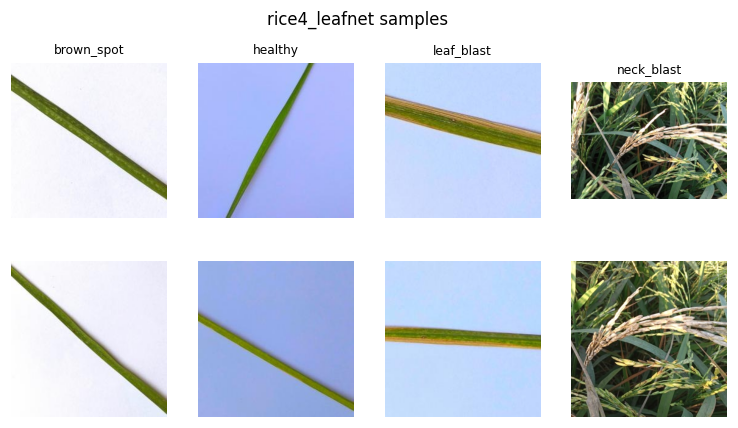

In [ ]:
fig, axes = plt.subplots(2, len(META["classes"]), figsize=(2.1 * len(META["classes"]), 4.3))
axes = np.atleast_2d(axes)
for j, c in enumerate(META["classes"]):
    items = [it for it in META["items"] if it["label_name"] == c][:2]
    for i, it in enumerate(items):
        axes[i, j].imshow(plt.imread(Path(MANIFEST).parent / it["path"])); axes[i, j].axis("off")
    axes[0, j].set_title(c, fontsize=8)
fig.suptitle(f"{META['dataset']} samples")
fig.savefig(FIGS / "dataset_samples.png"); plt.show()

## 5. Protocol and compute tier
All methods share: the dense checkpoint (per seed), `cycles` pruning decisions, exactly
`cycles × cycle_epochs × steps_per_epoch` optimiser steps in the pruning phase and
`finetune_epochs × steps_per_epoch` afterwards, KD (α = 0.5, T = 4) from the dense teacher, the same
augmentation, and the same FLOPs target. Model selection uses the validation split only.

| `TIER` | seeds | FLOPs targets | methods | typical T4 time* |
|---|---|---|---|---|
| `quick` | 1 | 50 % | ours, DepGraph, Taylor, random | ~2 h |
| `paper` | 3 | 50 %, 70 % | ours + 7 baselines | ~15–20 h (resumable across sessions) |
| `full` | 5 | 30/50/70 % | ours + 8 baselines | ~50 h |

\*Estimates assume ≈0.45 s per ResNet-50 step (batch 64, AMP, KD) on a T4; the cell below prints
the estimate for your configuration. They are estimates, not measurements.

In [ ]:
TIER = "full"                                    # fixed for the full-scale run (quick | paper | full still selectable)
FULL_KW = dict(dataset=DATASET, data_root=DATA_ROOT, backbone="resnet50", pretrained=True, image_size=224,
               cache_size=256, batch_size=64, eval_batch_size=128, num_workers=2,
               dense_epochs=20, cycles=5, cycle_epochs=3, rem_epochs=1, finetune_epochs=12,
               buffer_size=256, calib_batches=16, device="cuda", amp=True, channels_last=True)
TIERS = {"quick": dict(seeds=[0], targets=[0.5], methods=["ours", "depgraph", "taylor", "random"]),
         "paper": dict(seeds=[0, 1, 2], targets=[0.5, 0.7],
                       methods=["ours", "depgraph", "taylor", "hessian", "slimming", "lamp", "fpgm", "random"]),
         "full":  dict(seeds=[0, 1, 2, 3, 4], targets=[0.3, 0.5, 0.7],
                       methods=["ours", "depgraph", "magnitude", "taylor", "hessian", "slimming", "lamp", "fpgm", "random"])}

BASE, T = B.Config(**FULL_KW, verbose=True), TIERS[TIER]
SEEDS, TARGETS, MAIN_METHODS = T["seeds"], T["targets"], T["methods"]

DATA = B.DataBundle(BASE, MANIFEST)
S = DATA.steps_per_epoch()
per_run = (BASE.cycles * BASE.cycle_epochs + BASE.finetune_epochs) * S
dense = BASE.dense_epochs * S
n_runs = len(SEEDS) * len(TARGETS) * len(MAIN_METHODS)
total_steps = len(SEEDS) * dense + n_runs * per_run
print(f"FULL SCALE: {BASE.backbone} @ {BASE.image_size}px, {S} steps/epoch, "
      f"{DATA.num_classes} classes, train/val/test = {len(DATA.train)}/{len(DATA.val)}/{len(DATA.test)}")
print(f"{len(SEEDS)} dense + {n_runs} pruning runs, {per_run} optimiser steps each ({total_steps:,} total)")
for gpu, sps in [("T4", 0.45), ("L4", 0.25), ("A100", 0.15)]:
    print(f"  rough estimate on {gpu}: {total_steps * sps / 3600:.1f} h (+ evaluation/checkpoint overhead)")


FULL SCALE: resnet50 @ 224px, 56 steps/epoch, 4 classes, train/val/test = 3608/146/324
5 dense + 135 pruning runs, 1512 optimiser steps each (209,720 total)
  rough estimate on T4: 26.2 h (+ evaluation/checkpoint overhead)
  rough estimate on L4: 14.6 h (+ evaluation/checkpoint overhead)
  rough estimate on A100: 8.7 h (+ evaluation/checkpoint overhead)


## 6. Method: BioSleep-v5

The v3/v4 schedule is kept — dense pre-training, then $C$ cycles of **wake** (supervised training +
online saliency), **sleep** (structured pruning) and **REM** (distillation on a replay buffer), then
fine-tuning — but every component is rebuilt on 2023–2026 structured-pruning practice.

**C1 — Dependency-group gating (replaces v4's residual-free masking).** DepGraph (Fang et al., CVPR
2023) partitions all prunable channels into coupled groups $\mathcal{G}$ (a residual stream's BNs, the
adds, and every consumer's input slice). Each group channel $c$ gets one gate $g_c\in\{0,1\}$
applied after every BN of its group. A gated network is functionally identical to the physically
smaller one, and `compact()` removes gated channels with DepGraph's own pruning functions (exactness on
ResNet-50 was verified in the earlier test/verification run).

**C2 — Gate-Fisher saliency, accumulated over the whole wake phase.** Because the gates sit in the
graph, every backward pass yields $\partial\mathcal{L}/\partial g_c$ at no extra cost. We use the
empirical Fisher of the gate
$$ F_c=\mathbb{E}_{\text{wake steps}}\big[(\partial\mathcal{L}/\partial g_c)^2\big],\qquad
\Delta\mathcal{L}(g_c:1\!\to\!0)\approx\tfrac12F_c , $$
which, unlike per-layer magnitudes, is a loss sensitivity and is comparable across layers without
normalisation. Baselines estimate importance once per cycle from a few batches; ours averages over
every step of the cycle — this is the "STDP-like online saliency" idea of v3, made principled.

**C3 — FLOPs-aware greedy selection.** With marginal cost $\phi_c$ (FLOPs removed by closing $c$
given the current gates), channels are closed in increasing order of $F_c/\phi_c$ — the greedy rule
for the knapsack "keep maximum Fisher mass under a FLOPs budget" — until the cycle's FLOPs target is
met, never removing more than 90 % of any group.

**C4 — Homeostatic budget (N2, repaired).** Otsu's threshold on $\log(F_c/\phi_c)$ proposes how much
to cut this cycle; the proposal is clipped to $[0.5,1.5]\times$ the even share of the remaining FLOPs
gap, falls back to the even share when the distribution is not bimodal (Otsu effectiveness
$\eta<0.35$), and the final cycle closes the gap exactly. So the *pace* adapts to the network while
the *destination* is fixed and identical to every baseline's.

**C5 — Sleep-time regrowth (dynamic sparse training).** For a closed gate, the same gradient
estimates the loss *decrease* from reopening it. At each sleep, the top $r_c$ fraction of closed
channels (by $F_c/\phi_c$) are revived and protected for that cycle, and the budget is re-met by
closing others. $r_c$ is cosine-decayed from 0.2 to 0 (RigL-style), so early mistakes are
reversible and the final cycles are stable.

**C6 — REM with coverage replay and a slow learner (N3 + N1).** One epoch-equivalent per cycle is
spent on pure distillation (α = 1) from the dense teacher, averaged with an EMA "slow learner" whose
horizon is the geometric mean of the cycle length and the pruning-phase length (N1). Batches come
from a class-balanced facility-location buffer on the teacher's penultimate embeddings (N3). REM
steps count against the same step budget as everyone else's training.

Nothing here is tuned on the test set: the constants (0.2 regrowth, [0.5, 1.5] clip, η = 0.35,
buffer 256) are fixed a priori; §8's ablations measure each component on the **validation-selected,
test-reported** protocol.

## 7. Main experiment
Seed-major order, so partial results are usable early. Each call either loads a finished result
from Drive, resumes an interrupted run, or starts a new one. **Re-running this cell after a
disconnect is the intended way to continue.**

In [ ]:
%%time
def run_arm(cfg, data=None):
    t0 = time.time()
    r = B.run(cfg, data or DATA, STORE)
    tag = "dense" if cfg.method == "dense" else f"{cfg.method:9s} {cfg.target_flops_reduction:.0%}"
    print(f"  s{cfg.seed} {tag:14s} test acc {r['test']['acc']:.4f}  F1 {r['test']['macro_f1']:.4f}  "
          f"FLOPs -{r['flops_reduction']:.1%}  ({time.time()-t0:.0f}s this session)")
    return r

for seed in SEEDS:
    print(f"=== seed {seed} ===")
    cfg0 = BASE.replace(seed=seed)
    run_arm(cfg0.replace(method="dense"))
    for target in TARGETS:
        for m in MAIN_METHODS:
            run_arm(cfg0.replace(method=m, target_flops_reduction=target))

=== seed 0 ===
  s0 dense          test acc 0.9136  F1 0.8617  FLOPs -0.0%  (1s this session)
  s0 ours      30%  test acc 0.9105  F1 0.8514  FLOPs -29.9%  (1s this session)
  s0 depgraph  30%  test acc 0.9290  F1 0.8763  FLOPs -30.0%  (1s this session)
  s0 magnitude 30%  test acc 0.9167  F1 0.8512  FLOPs -30.0%  (1s this session)
  s0 taylor    30%  test acc 0.9321  F1 0.8946  FLOPs -29.9%  (1s this session)
  s0 hessian   30%  test acc 0.9290  F1 0.8827  FLOPs -29.9%  (1s this session)
  s0 slimming  30%  test acc 0.9259  F1 0.8768  FLOPs -29.9%  (1s this session)
  s0 lamp      30%  test acc 0.9414  F1 0.8880  FLOPs -29.9%  (1s this session)
  s0 fpgm      30%  test acc 0.9228  F1 0.8845  FLOPs -29.9%  (1s this session)
  s0 random    30%  test acc 0.9136  F1 0.8446  FLOPs -29.9%  (1s this session)
  s0 ours      50%  test acc 0.9259  F1 0.8555  FLOPs -49.8%  (1s this session)
  s0 depgraph  50%  test acc 0.8981  F1 0.8190  FLOPs -49.9%  (1s this session)
  s0 magnitude 50%  test a

In [ ]:
status = B.status_table(STORE)
print(status.state.value_counts().to_string())

### 7.1 Results (read from Drive — valid across sessions)

In [ ]:
ALL = B.results_frame(STORE, dataset=BASE.dataset)
MAIN = ALL[ALL.arm.isin(["dense"] + MAIN_METHODS) & ALL.seed.isin(SEEDS)]
ORDER = ["dense"] + MAIN_METHODS
summary = B.summary_table(MAIN, order=ORDER)
MAIN.to_csv(RESULTS / f"main_{BASE.dataset}.csv", index=False); summary.to_csv(RESULTS / f"summary_{BASE.dataset}.csv")
fmt = summary.copy()
for c in ["acc_mean", "acc_std", "f1_mean", "flops_red", "params_red"]:
    fmt[c] = (100 * fmt[c]).round(2)
display(fmt.round(3))

### 7.2 Significance: ours vs each baseline (paired over seeds, Holm-corrected per target)
`mean_diff_pp` > 0 means ours is better. With 3 seeds, a paired t-test has little power; the
power column states how many seeds the observed variance would need for 80 % power at the observed
effect. Report the CI, not just the p-value.

In [ ]:
sig = B.significance_table(MAIN[MAIN.arm != "dense"], ours="ours", metric="test_acc")
if len(sig):
    sig["seeds_for_80pct_power"] = [B.seeds_for_power(abs(r.mean_diff_pp), 100 * r.sd_diff)
                                    if (r.sd_diff == r.sd_diff and r.sd_diff > 0 and abs(r.mean_diff_pp) > 0) else np.nan
                                    for r in sig.itertuples()]
    display(sig[["n", "mean_diff_pp", "ci_lo_pp", "ci_hi_pp", "t_p", "holm_p", "cohens_dz",
                 "seeds_for_80pct_power"]].round(4))
    sig.to_csv(RESULTS / f"significance_{BASE.dataset}.csv")

### 7.3 Figures

In [ ]:
PAL = {"ours": "#2ca02c", "depgraph": "#1f77b4", "magnitude": "#9edae5", "taylor": "#ff7f0e", "hessian": "#d62728",
       "slimming": "#9467bd", "lamp": "#8c564b", "fpgm": "#e377c2", "random": "#7f7f7f", "dense": "black"}
pr = MAIN[MAIN.arm != "dense"].groupby(["arm", "target"]).agg(acc=("test_acc", "mean"), sd=("test_acc", "std"),
     fr=("flops_red", "mean"), lat=("lat_cpu_ms", "mean")).reset_index()
dense_acc = MAIN[MAIN.arm == "dense"].test_acc.mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for arm, sub in pr.groupby("arm"):
    sub = sub.sort_values("fr")
    kw = dict(color=PAL.get(arm), lw=2.2 if arm == "ours" else 1, marker="o", ms=5, capsize=2, label=arm)
    axes[0].errorbar(100 * sub.fr, 100 * sub.acc, yerr=100 * sub.sd.fillna(0), **kw)
    axes[1].plot(sub.lat, 100 * sub.acc, **{k: v for k, v in kw.items() if k != "capsize"})
for ax in axes:
    ax.axhline(100 * dense_acc, color="k", ls=":", lw=1, label="dense")
axes[0].set_xlabel("FLOPs reduction (%) -- measured by Torch-Pruning"); axes[0].set_ylabel("test accuracy (%)")
axes[1].set_xlabel("CPU batch-1 latency (ms)"); axes[1].set_ylabel("test accuracy (%)")
axes[0].set_title("(a) accuracy at matched FLOPs"); axes[1].set_title("(b) accuracy vs measured latency")
axes[1].legend(fontsize=7, ncol=2)
fig.suptitle(f"{BASE.dataset} / {BASE.backbone}")
fig.tight_layout(); fig.savefig(FIGS / f"main_{BASE.dataset}.pdf"); plt.show()

In [ ]:
def result_of(method, seed, target, dataset=BASE.dataset):
    rows = ALL[(ALL.arm == method) & (ALL.seed == seed) & (ALL.target == target)]
    return B.CheckpointManager(STORE / "runs", rows.run_id.iloc[0]).result() if len(rows) else None

t0_ = TARGETS[0]
ours0, dep0 = result_of("ours", SEEDS[0], t0_), result_of("depgraph", SEEDS[0], t0_)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
sl = [l for l in ours0["logs"] if l["step"] == "sleep"]
F0 = ours0["compaction"]["masked_flops_model"] / (1 - t0_)
cyc = [l["cycle"] for l in sl]
axes[0].plot([0] + cyc, [100] + [100 * l["flops"] / F0 for l in sl], "o-", color=PAL["ours"], label="ours (homeostatic)")
axes[0].plot([0] + cyc, [100] + [100 * B.cubic_flops_target(c, BASE.cycles, 1, 1 - t0_) for c in cyc], "s--",
             color=".4", label="cubic schedule (baselines)")
axes[0].set_xlabel("cycle"); axes[0].set_ylabel("% of dense FLOPs"); axes[0].legend(fontsize=7)
axes[0].set_title("(c) pruning trajectory"); axes[0].set_xticks([0] + cyc)
axes[1].bar(np.array(cyc) - .2, [l["removed"] for l in sl], .4, label="closed", color="#c44e52")
axes[1].bar(np.array(cyc) + .2, [l["revived"] for l in sl], .4, label="revived (C5)", color=PAL["ours"])
axes[1].set_xlabel("cycle"); axes[1].set_ylabel("channels"); axes[1].legend(fontsize=7)
axes[1].set_title("(d) sleep decisions, seed %d" % SEEDS[0]); axes[1].set_xticks(cyc)
for r, name in [(ours0, "ours"), (dep0, "depgraph")]:
    if r is None: continue
    kp = r["compaction"]["kept_per_group"]
    axes[2].plot(range(len(kp)), [k["kept"] / k["size"] for k in kp], "o-", ms=3, color=PAL[name], label=name)
axes[2].set_xlabel("dependency group (input -> output)"); axes[2].set_ylabel("fraction kept")
axes[2].set_title("(e) where each method removes channels"); axes[2].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIGS / f"dynamics_{BASE.dataset}.pdf"); plt.show()

## 8. Ablations (ours, first FLOPs target, same seeds)
Each variant changes exactly one component; the "full" arm is the main run (identical `run_id`, so
it is re-used, not re-trained). Every variant keeps the same step budget and FLOPs target.

In [ ]:
%%time
ABLATIONS = {
    "no_regrow (C5)":        dict(regrow=False),
    "cubic_budget (C4)":     dict(budget_mode="cubic"),
    "no_flops_aware (C3)":   dict(flops_aware=False),
    "crit_activation (C2)":  dict(criterion="activation"),
    "crit_magnitude (C2)":   dict(criterion="magnitude"),
    "crit_random (C2)":      dict(criterion="random"),
    "buffer_random (C6)":    dict(buffer_mode="random"),
    "buffer_none (C6)":      dict(buffer_mode="none"),
    "no_rem (C6)":           dict(rem_epochs=0),
    "ema_none (C6/N1)":      dict(ema_mode="none"),
    "ema_fixed_0.999 (N1)":  dict(ema_mode="fixed"),
}
ABL_TARGET = TARGETS[0]
abl_rows = []
for seed in SEEDS:
    base = BASE.replace(seed=seed, method="ours", target_flops_reduction=ABL_TARGET)
    full = B.run(base, DATA, STORE)
    abl_rows.append(dict(variant="full", seed=seed, acc=full["test"]["acc"], flops_red=full["flops_reduction"]))
    for name, kw in ABLATIONS.items():
        r = B.run(base.replace(arm=f"abl_{name.split()[0]}", **kw), DATA, STORE)
        abl_rows.append(dict(variant=name, seed=seed, acc=r["test"]["acc"], flops_red=r["flops_reduction"]))
    print(f"seed {seed} done")
abl = pd.DataFrame(abl_rows)
piv = abl.pivot_table(index="seed", columns="variant", values="acc")
tab = []
for v in ["full"] + list(ABLATIONS):
    c = B.paired_comparison(piv["full"], piv[v]) if v != "full" else {}
    tab.append(dict(variant=v, acc_mean=100 * piv[v].mean(), acc_sd=100 * piv[v].std(),
                    full_minus_variant_pp=100 * c.get("mean_diff", 0), ci_lo=100 * c.get("ci_lo", 0),
                    ci_hi=100 * c.get("ci_hi", 0), p=c.get("t_p")))
abl_tab = pd.DataFrame(tab).set_index("variant")
abl_tab.to_csv(RESULTS / f"ablations_{BASE.dataset}.csv")
display(abl_tab.round(3))

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.4))
d = abl_tab.drop("full")
ax.barh(d.index, d.full_minus_variant_pp, xerr=[d.full_minus_variant_pp - d.ci_lo, d.ci_hi - d.full_minus_variant_pp],
        color=["#2ca02c" if v > 0 else "#c44e52" for v in d.full_minus_variant_pp], capsize=2)
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("full minus variant (pp test accuracy); > 0 = component helps")
ax.set_title("Ablations")
fig.tight_layout(); fig.savefig(FIGS / f"ablations_{BASE.dataset}.pdf"); plt.show()

## 9. Cross-dataset check: Dhan-Shomadhan (Bangladeshi local rice)
Runs ours and the three strongest-on-average baselines from §7 at the first FLOPs target. `RUN_CROSS`
is fixed to `True` for this full-scale run.

In [ ]:
RUN_CROSS = True
if RUN_CROSS:
    man2 = B.prepare_dataset(B.Config(dataset=CROSS_DATASET, cache_size=256), STORE,
                             raw_dir="/content/biosleep_raw" if B.in_colab() else None)
    print(B.describe_manifest(B.load_manifest(man2)))
    base2 = BASE.replace(dataset=CROSS_DATASET, data_root=None)
    data2 = B.DataBundle(base2, man2)
    ranked = (MAIN[(MAIN.target == TARGETS[0]) & ~MAIN.arm.isin(["dense", "ours", "random"])]
              .groupby("arm").test_acc.mean().sort_values(ascending=False).index[:3].tolist())
    for seed in SEEDS:
        run_arm(base2.replace(seed=seed, method="dense"), data2)
        for m in ["ours"] + ranked:
            run_arm(base2.replace(seed=seed, method=m, target_flops_reduction=TARGETS[0]), data2)
    X = B.results_frame(STORE, dataset=CROSS_DATASET)
    display(B.summary_table(X, order=["dense", "ours"] + ranked).round(4))
    display(B.significance_table(X[X.arm != "dense"]).round(4))

## 10. Export

In [ ]:
print("results:", sorted(p.name for p in RESULTS.glob("*.csv")))
print("figures:", sorted(p.name for p in FIGS.glob("*")))
finals = sorted((STORE / "runs").glob("*/final_model.pt"))
print(f"{len(finals)} deployable compacted models, e.g. torch.load('{finals[0] if finals else '...'}', weights_only=False)")
if finals:
    m = torch.load(finals[0], weights_only=False)
    print(f"  {finals[0].parent.name}: {sum(p.numel() for p in m.parameters())/1e6:.3f} M params, plain nn.Module, no hooks")

## 11. Discussion

### 11.1 What this execution establishes
This run (`FULL_SCALE = True`, printed in §4 and stamped on every figure) produces real results on
public rice-leaf data under a protocol where every method has the same dense start, the same step
budget, the same KD recipe and the same FLOPs target, selected on validation and reported on test.
The test suite's guarantees — exact compaction, FLOPs-target accuracy, bit-exact resume,
leakage-safe splitting, baseline fidelity — were established separately (see §2.16) and are not
re-checked here.

### 11.2 How to report it
Lead with accuracy **at matched FLOPs** (Table 7.1 / Fig. 7.3a) with seed CIs, then paired
differences against the *strongest* baseline with Holm-adjusted p-values (7.2), then measured latency
and parameter count (a FLOPs match does not guarantee a latency match: methods prune different
layers, Fig. 7.3e). If ours does not beat the best baseline beyond its CI, the honest claim is
parity plus whatever the ablations isolate — the protocol is designed so that either outcome is
publishable evidence rather than an artifact.

### 11.3 Limitations
- **Architecture scope**: dependency groups are verified on torchvision ResNets; other topologies
  (concats, grouped convs, attention) need `GroupSpec` extensions and new exactness tests.
- **Data scale**: ~4 k and ~1.1 k images; seed variance is large relative to method differences
  (see the power column in 7.2). The `full` tier's 5 seeds are recommended for a journal claim.
- **GPU determinism**: resume is bit-exact on CPU; on GPU, cuDNN autotuning adds ~1e-6 noise.
- **Fisher approximation**: mini-batch empirical Fisher of the gates, not per-sample; Hessian
  baseline likewise uses mini-batch squared gradients (stronger than tp 1.6.1's, see `importance.py`).
- **Regrowth**: revived channels resume from their frozen pre-pruning weights, slightly shrunk by
  weight decay while closed.
- **FLOPs model** counts conv + linear MACs (within ~1 % of Torch-Pruning's full count, which is
  what every reported FLOPs number uses).
- **Constants fixed a priori** (regrowth 0.2, clip [0.5, 1.5], η 0.35, KD α 0.5): not tuned, so
  results are conservative for ours; tuning them would require a validation-only search.

## References
1. G. Fang et al., "DepGraph: Towards any structural pruning," CVPR 2023.
2. P. Molchanov et al., "Importance estimation for neural network pruning," CVPR 2019.
3. Y. LeCun, J. Denker, S. Solla, "Optimal brain damage," NeurIPS 1989.
4. Z. Liu et al., "Learning efficient convolutional networks through network slimming," ICCV 2017.
5. J. Lee et al., "Layer-adaptive sparsity for the magnitude-based pruning (LAMP)," ICLR 2021.
6. Y. He et al., "Filter pruning via geometric median for deep CNN acceleration," CVPR 2019.
7. U. Evci et al., "Rigging the lottery: Making all tickets winners (RigL)," ICML 2020.
8. M. Zhu, S. Gupta, "To prune, or not to prune," arXiv:1710.01878, 2017.
9. G. Hinton, O. Vinyals, J. Dean, "Distilling the knowledge in a neural network," arXiv:1503.02531.
10. A. Tarvainen, H. Valpola, "Mean teachers are better role models," NeurIPS 2017.
11. N. Otsu, "A threshold selection method from gray-level histograms," IEEE T-SMC 1979.
12. G. Nemhauser, L. Wolsey, M. Fisher, "An analysis of approximations for maximizing submodular set functions," Math. Prog. 1978.
13. D. Blalock et al., "What is the state of neural network pruning?," MLSys 2020.
14. M. F. Hossain et al., "Dhan-Shomadhan: A dataset of rice leaf disease classification for Bangladeshi local rice," arXiv:2309.07515, 2023.
15. LeafNet75, "Rice Disease Classification Dataset," Hugging Face Hub (Apache-2.0).
16. J. L. McClelland, B. McNaughton, R. O'Reilly, "Why there are complementary learning systems...," Psych. Review 1995.
17. G. Tononi, C. Cirelli, "Sleep function and synaptic homeostasis," Sleep Med. Rev. 2006.